In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path().cwd().parent / 'data'
data = pd.read_csv(DATA_DIR / 'train.csv')

sns.set_theme()
sns.set_style("darkgrid")
colours = sns.color_palette("bright")

In [61]:
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [62]:
data.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [63]:
data.duplicated().sum()

np.int64(0)

In [64]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [65]:
y = data['SalePrice']
X = data.drop(columns=['SalePrice'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

CATERGORICAL_COLUMNS = [col for col in X_train.columns if ((X_train[col].dtype == 'object') | (X_train[col].dtype == 'str'))]
NUMERICAL_COLUMNS = [col for col in X_train.columns if ((X_train[col].dtype != 'str') & (X_train[col].dtype != 'object'))]
NUMERICAL_COLUMNS.remove('Id')

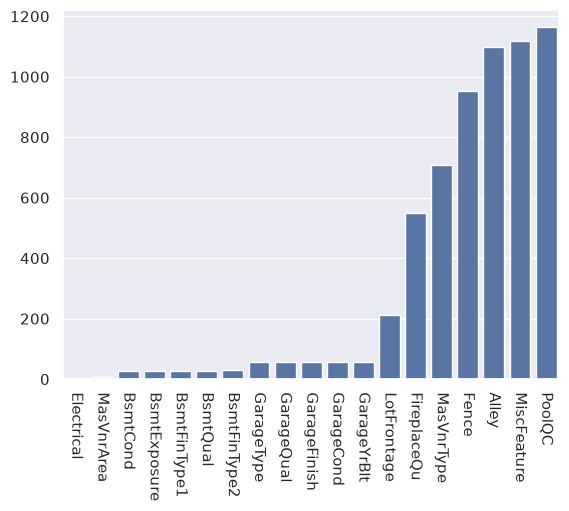

In [66]:
missing = X_train.isna().sum()
missing = (missing[missing > 0]).sort_values()
sns.barplot(missing)
plt.xticks(rotation=-90)
plt.show()

## Target analysis


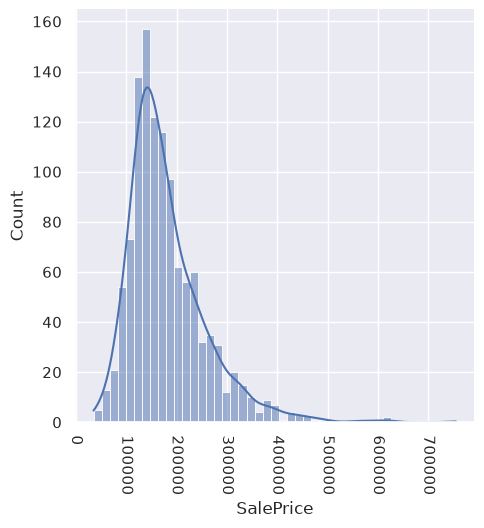

In [67]:
sns.displot(data=y_train, kde=True)
plt.xticks(rotation=-90)
plt.show()

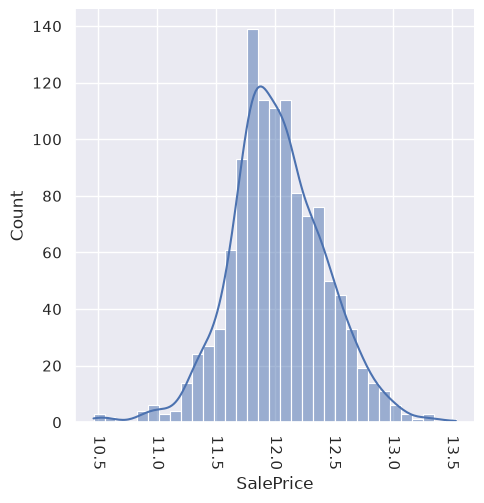

In [68]:
y_train_transformed = np.log(y_train)
sns.displot(data=y_train_transformed, kde=True)
plt.xticks(rotation=-90)
plt.show()

## Univariate analysis
### Discrete numerical analysis


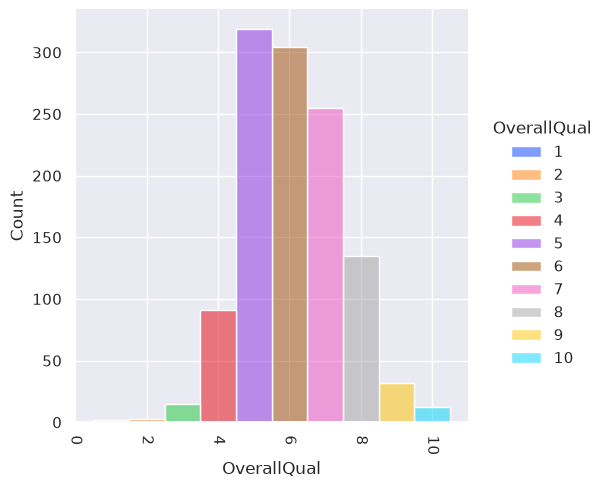

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


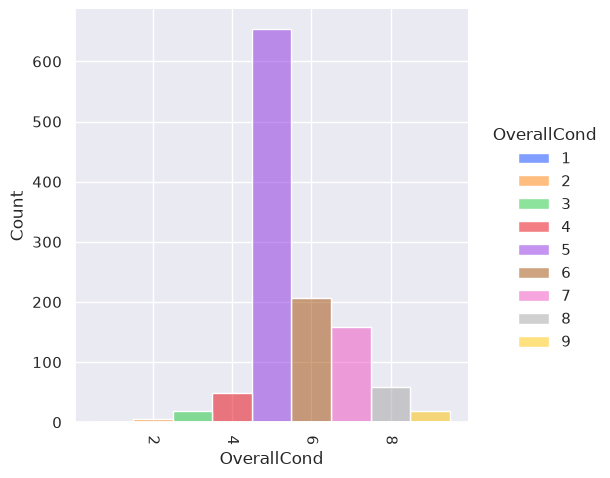

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


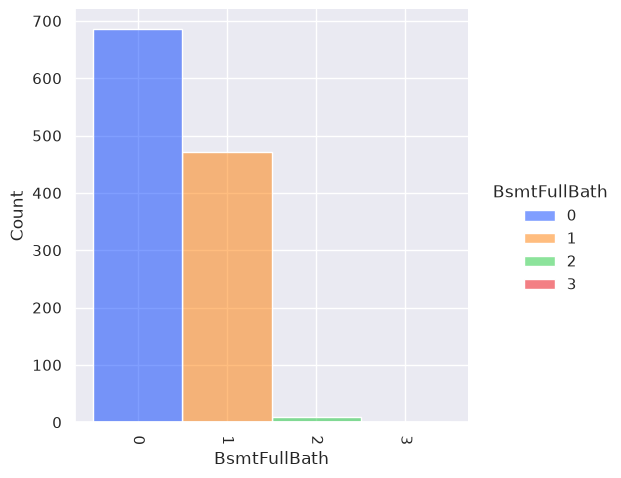

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


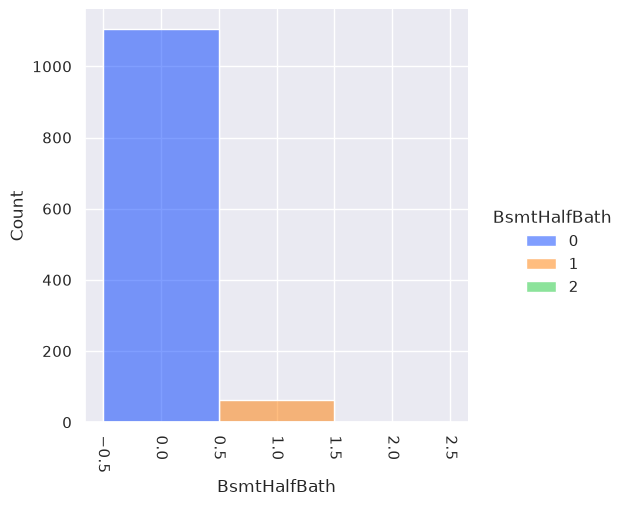

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


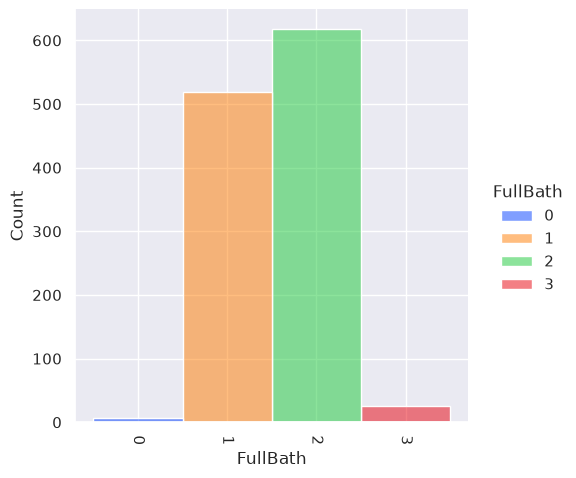

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


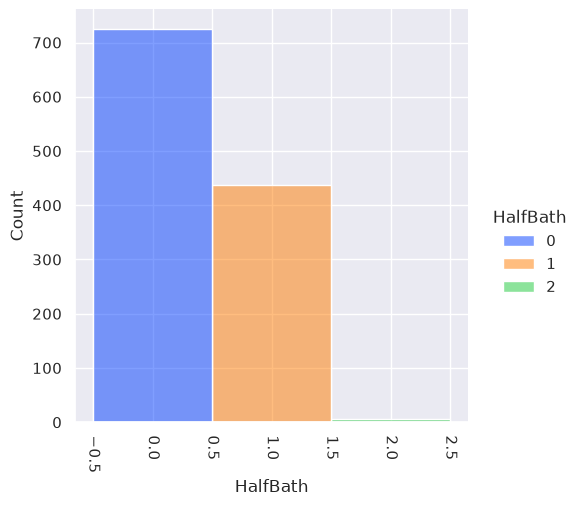

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


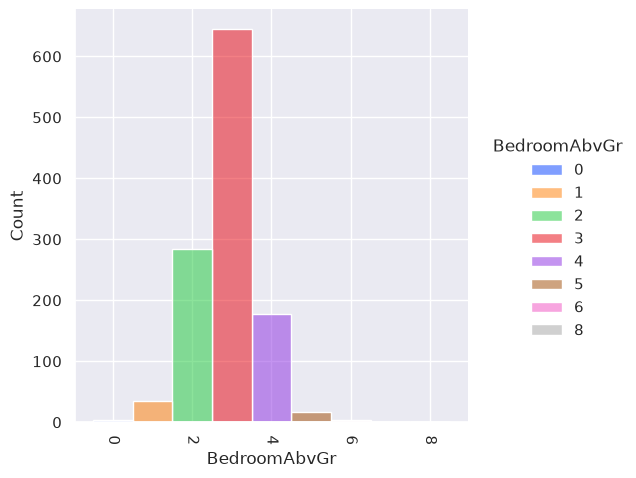

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


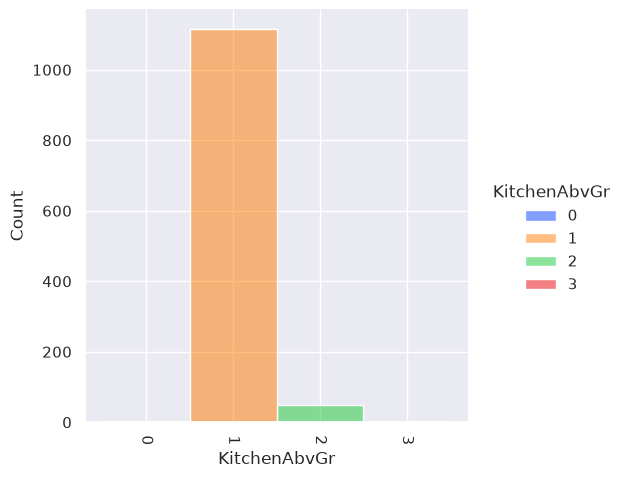

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: 
The palette list has fewer values (10) than needed (12) and will cycle, which may produce an uninterpretable plot.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


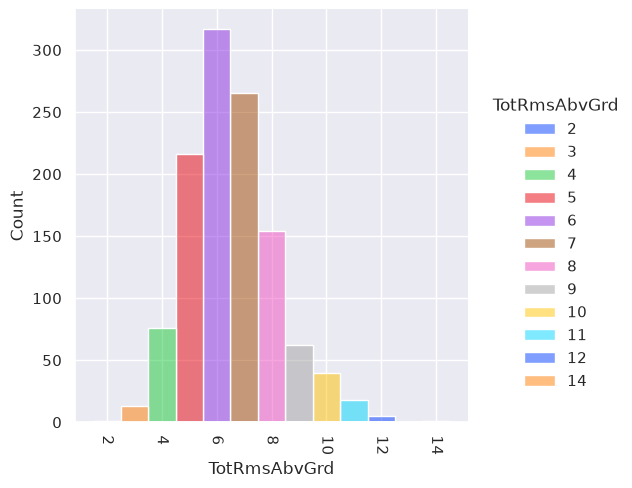

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


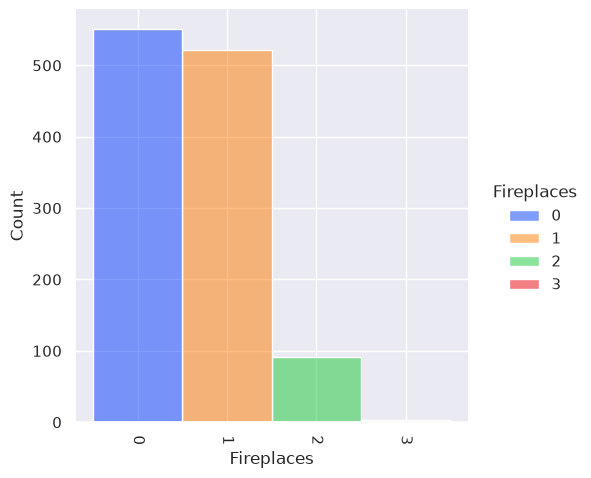

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


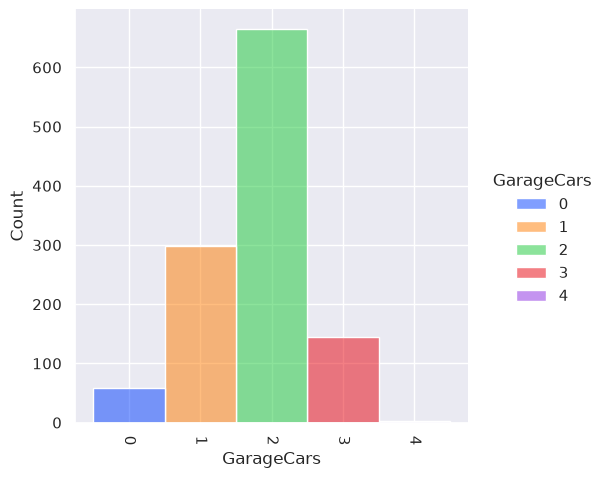

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: 
The palette list has fewer values (10) than needed (12) and will cycle, which may produce an uninterpretable plot.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


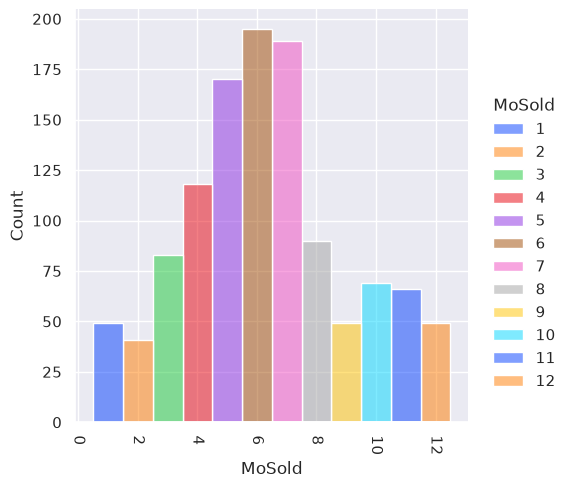

/tmp/ipykernel_16690/2934875539.py:8: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)


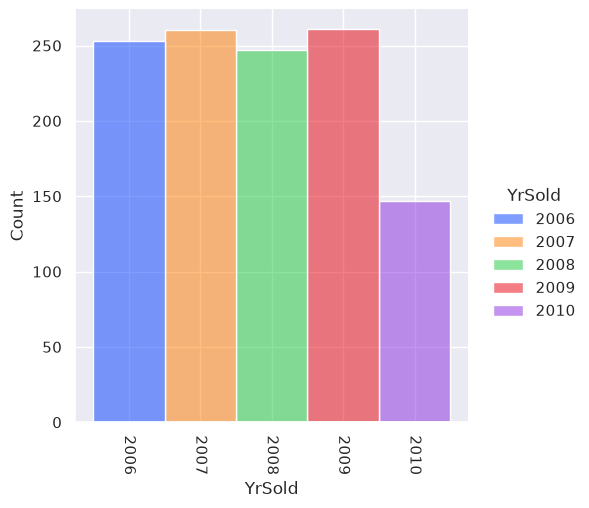

In [69]:
DISC_NUM_COLS = ['OverallQual','OverallCond','BsmtFullBath','BsmtHalfBath','FullBath','HalfBath',
                'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'MoSold', 'YrSold']
CONT_NUM_COLS = [col for col in NUMERICAL_COLUMNS if col not in DISC_NUM_COLS]



for col in DISC_NUM_COLS:
    sns.displot(data=X_train, x=col, discrete=True, hue=col, palette=colours)
    plt.xticks(rotation=-90)
    plt.show()

### Continous numerical analysis

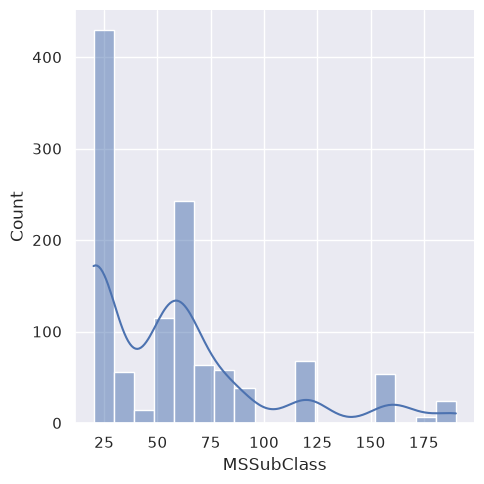

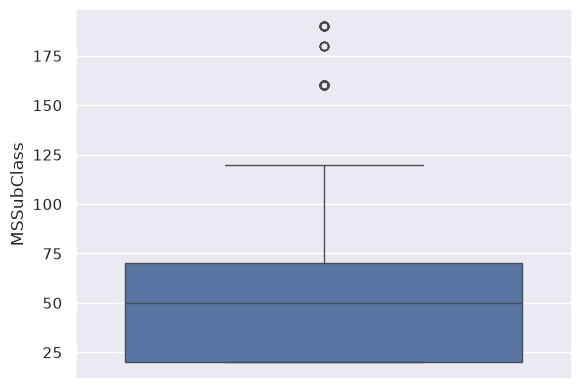

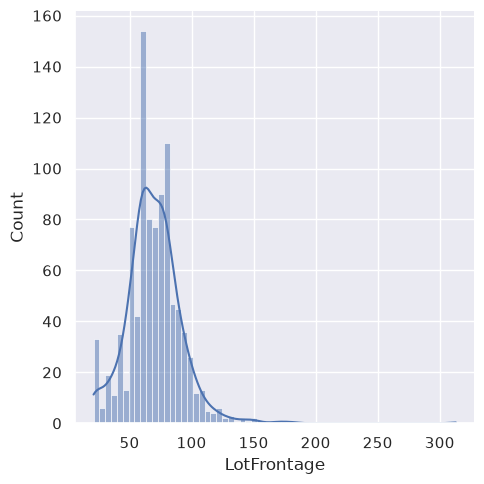

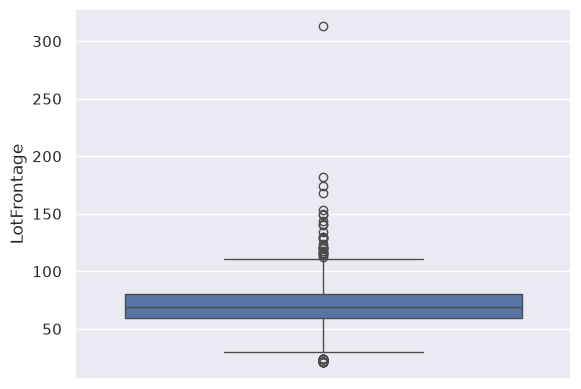

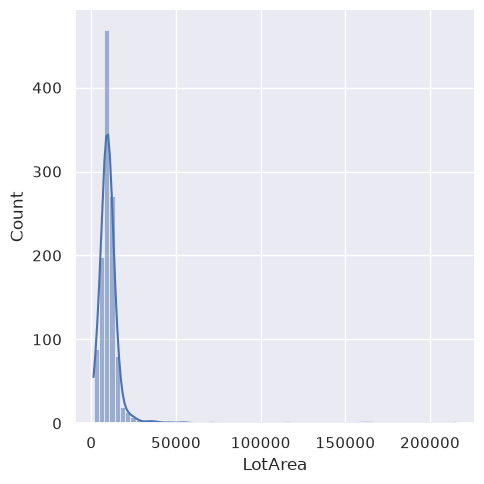

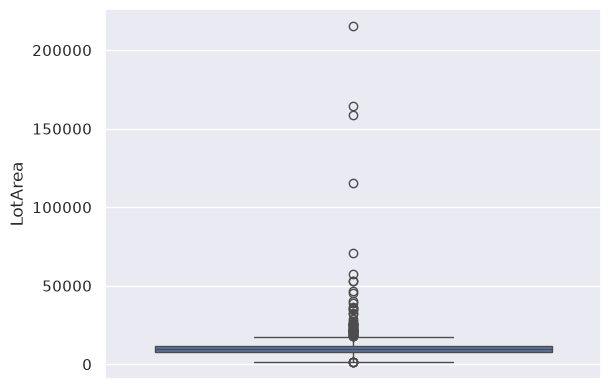

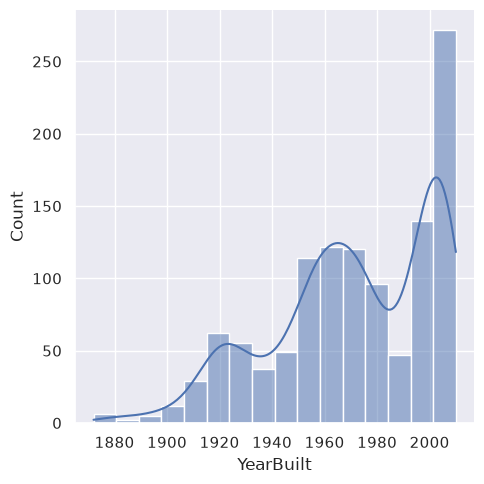

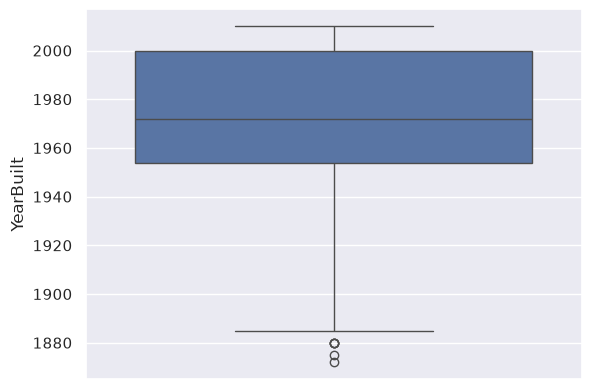

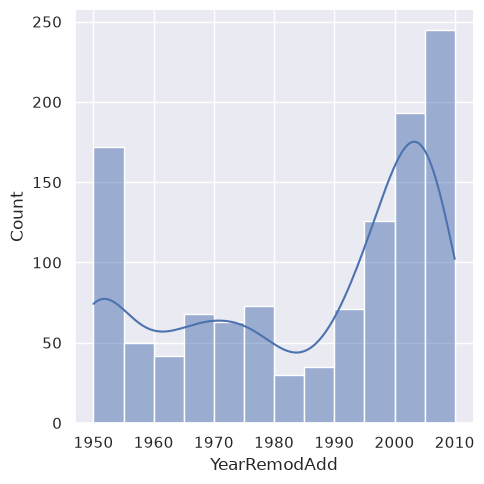

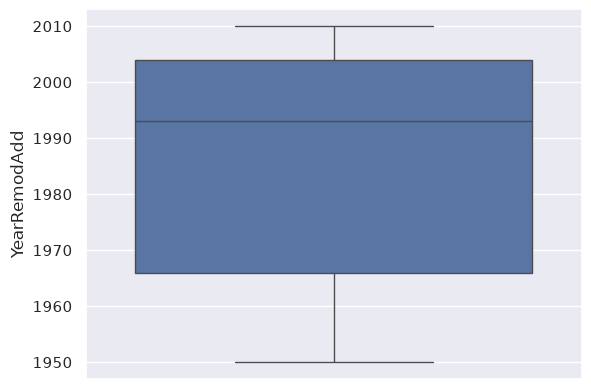

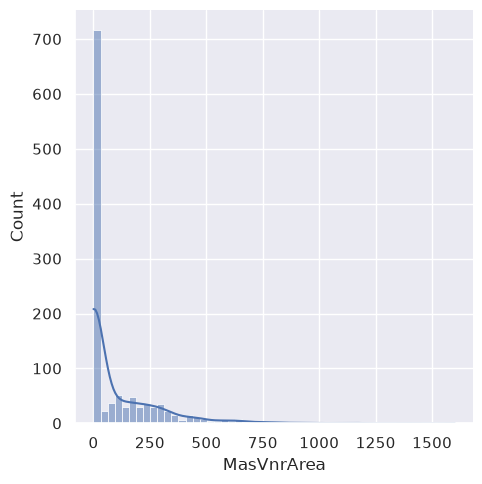

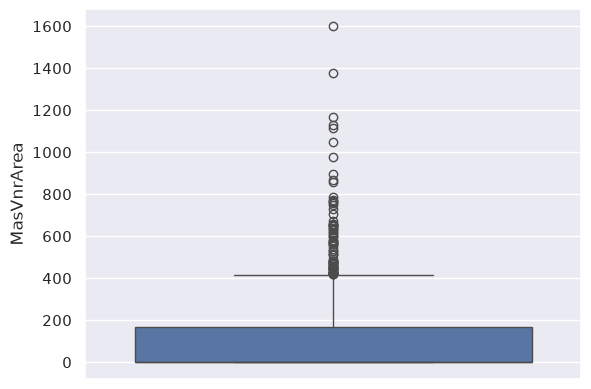

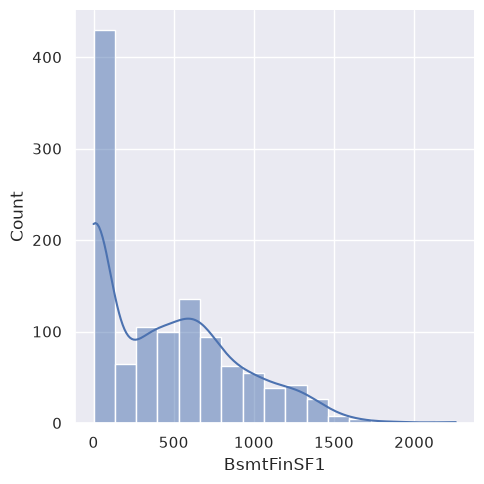

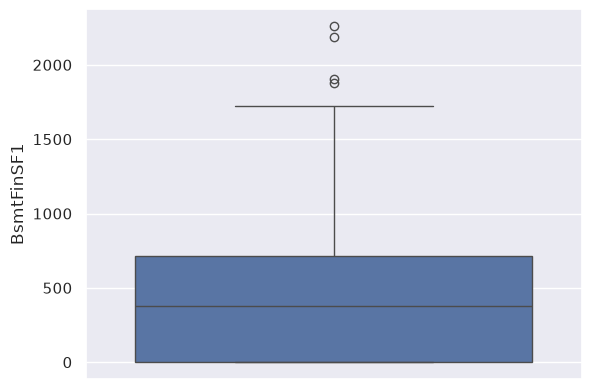

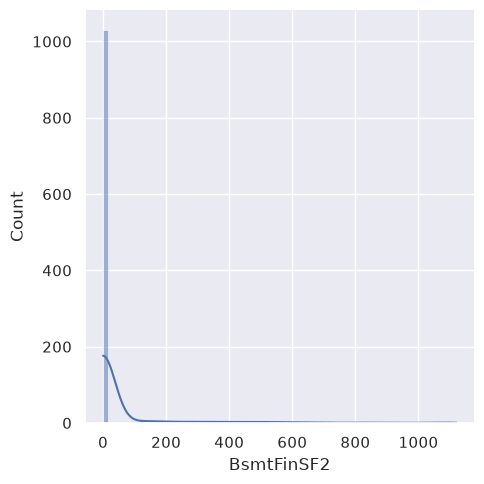

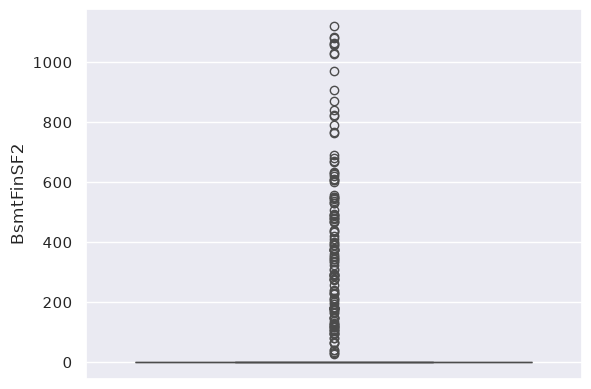

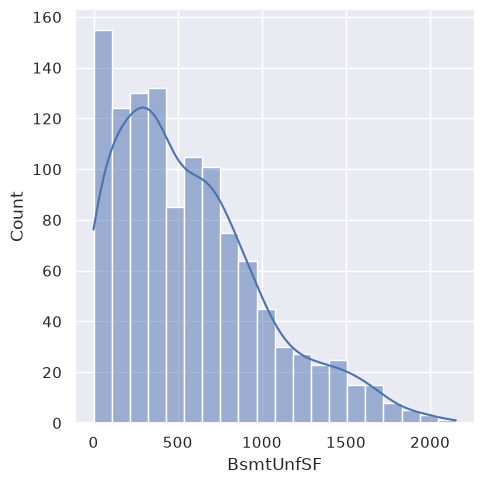

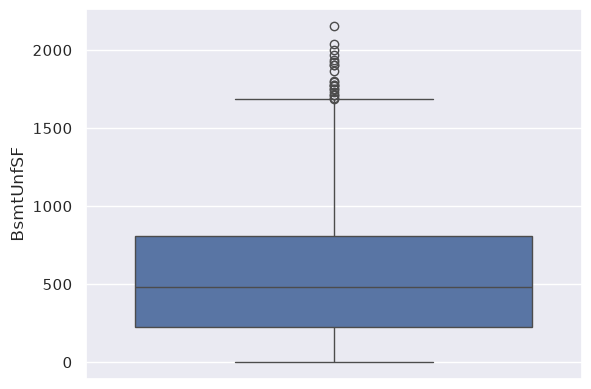

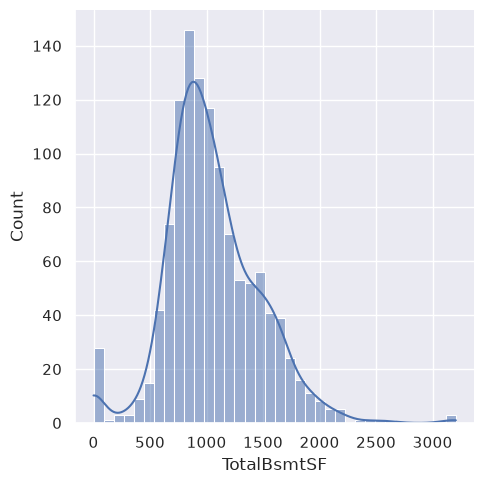

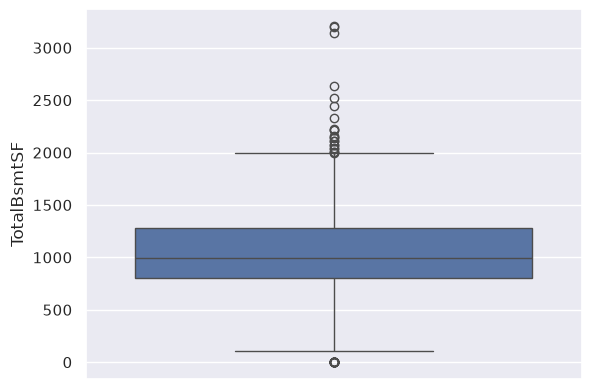

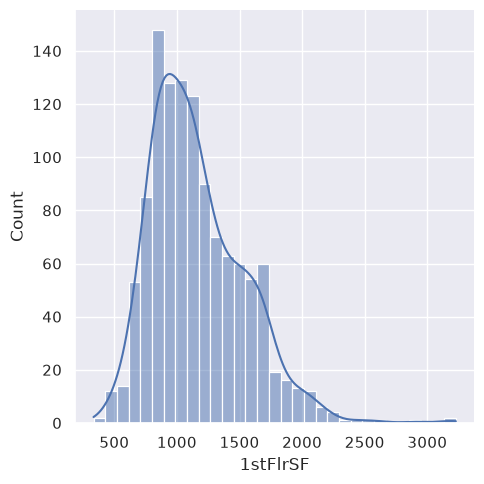

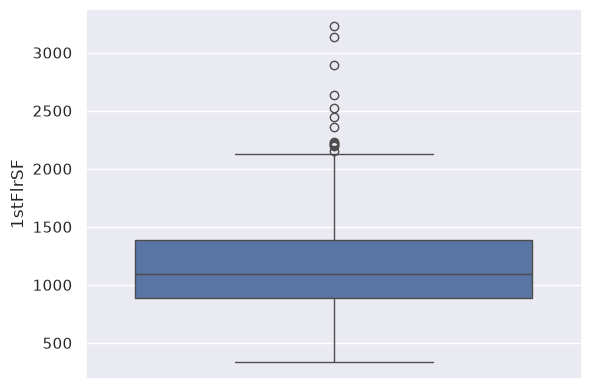

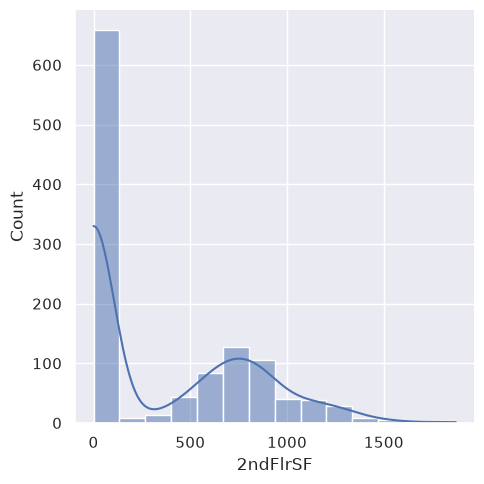

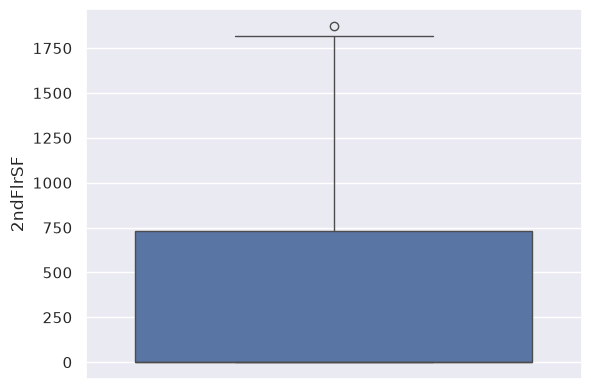

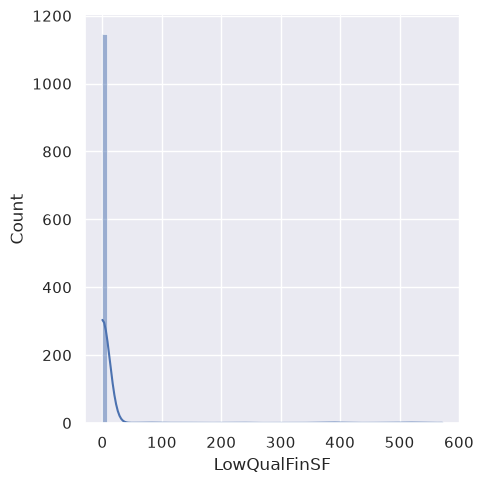

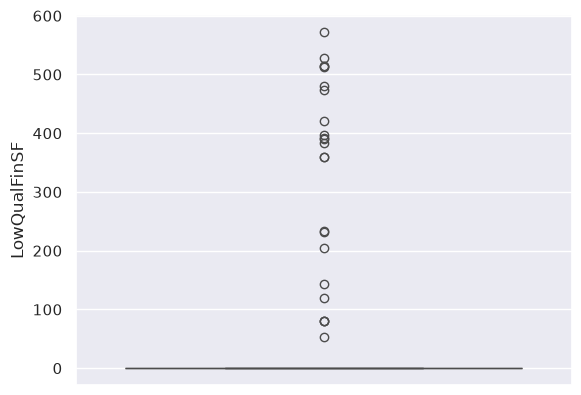

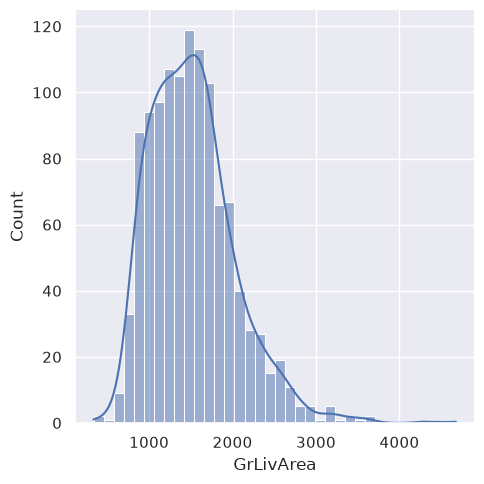

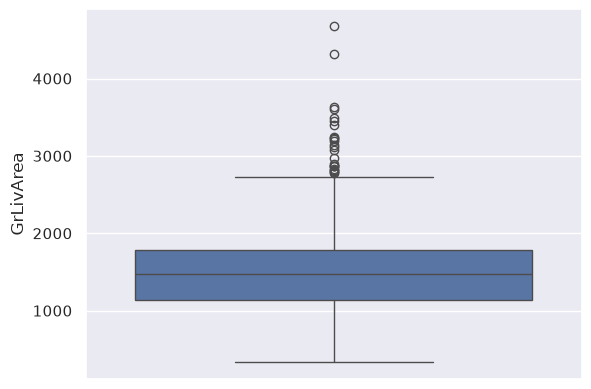

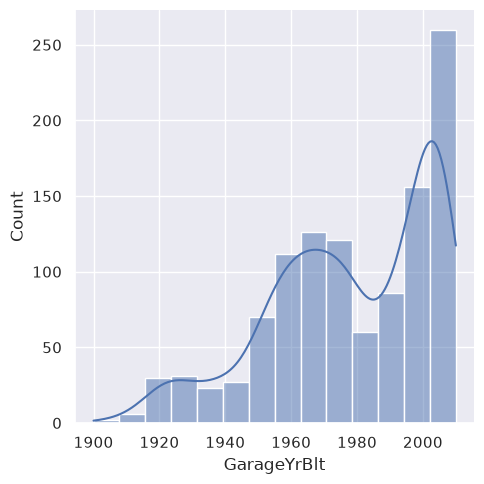

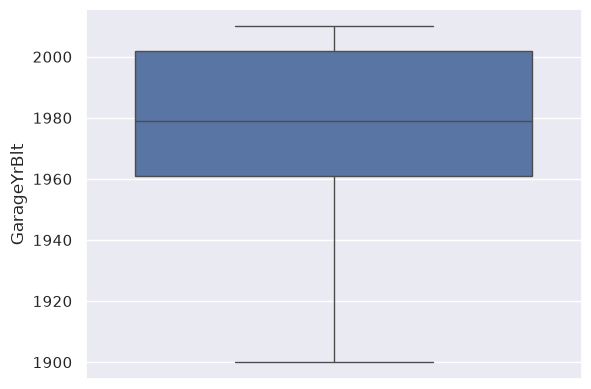

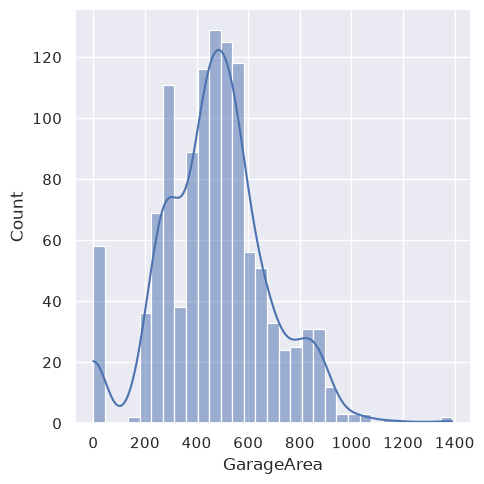

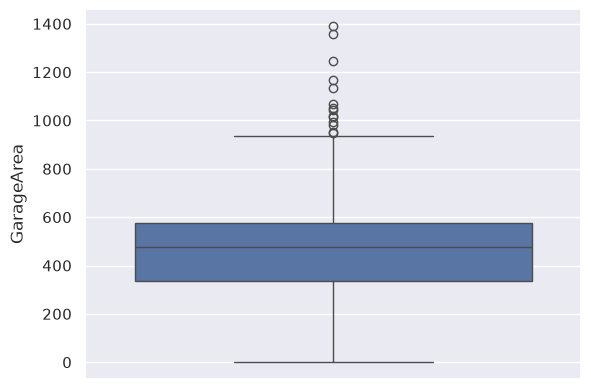

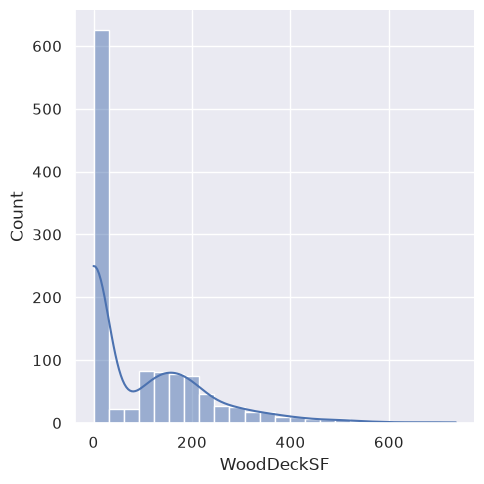

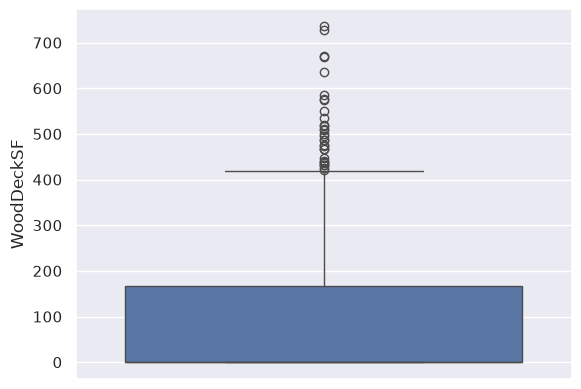

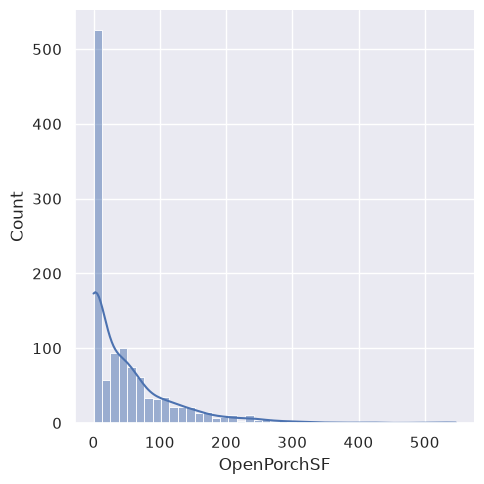

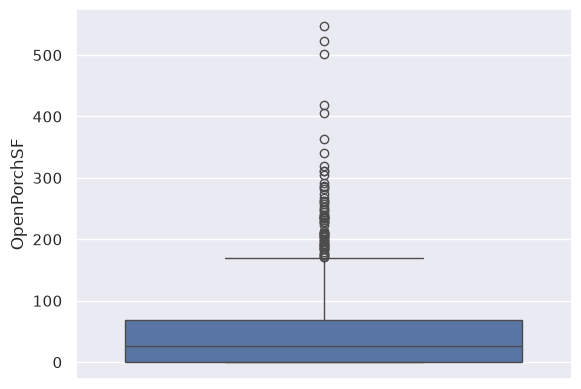

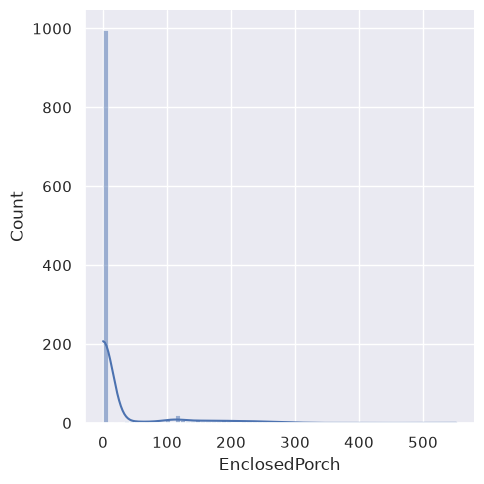

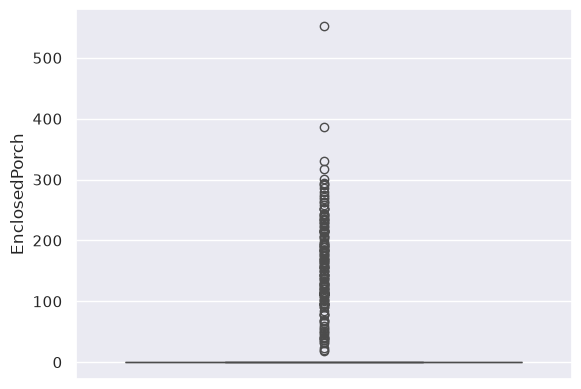

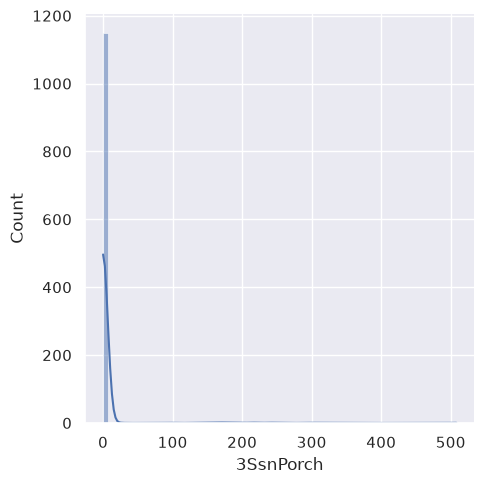

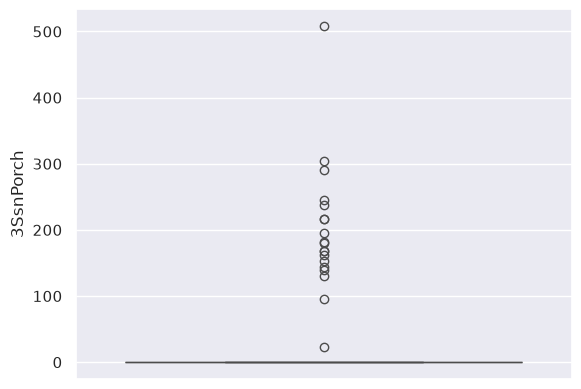

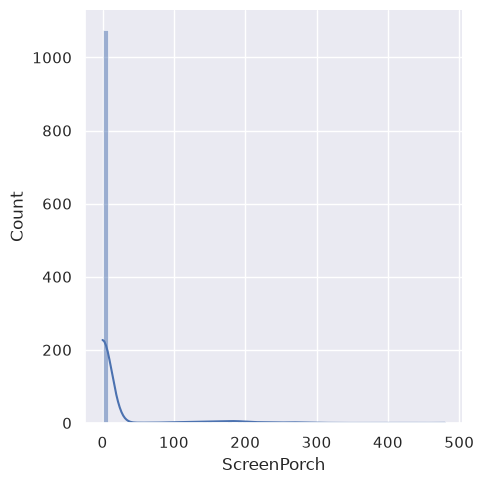

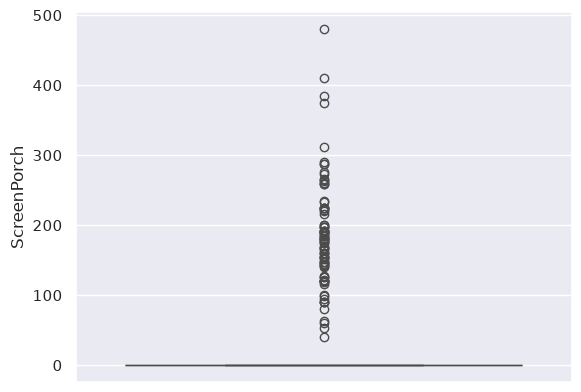

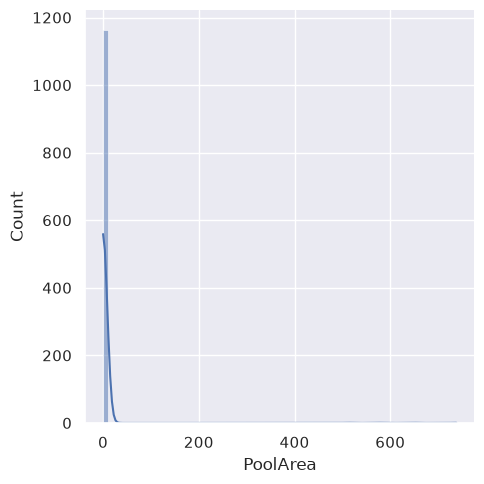

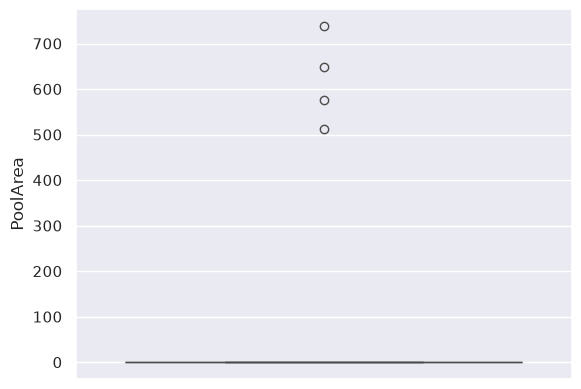

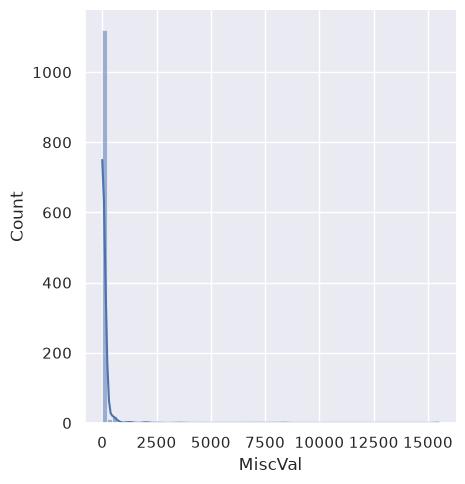

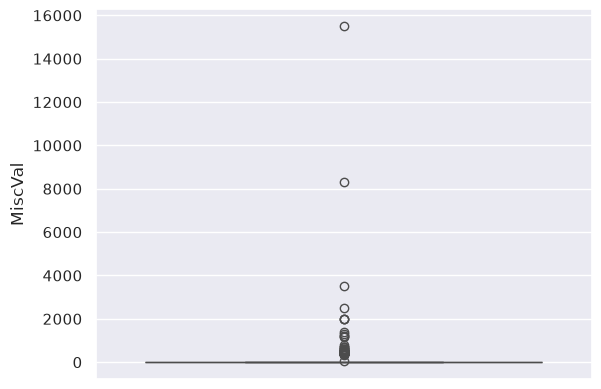

In [70]:
for col in CONT_NUM_COLS:
    sns.displot(data=X_train, x=col, kde=True)
    plt.show()
    sns.boxplot(data=X_train, y=col)
    plt.show()


### Categorical Analysis

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


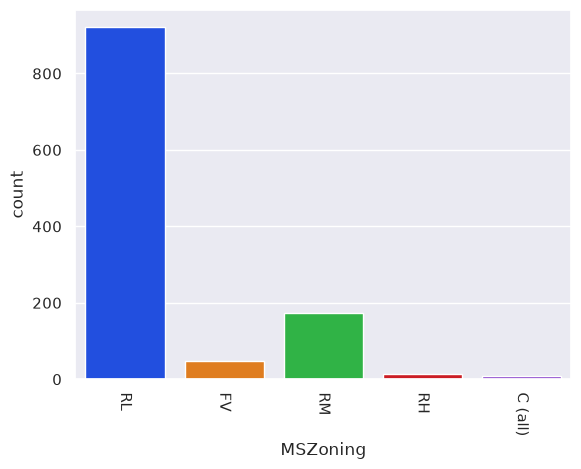

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


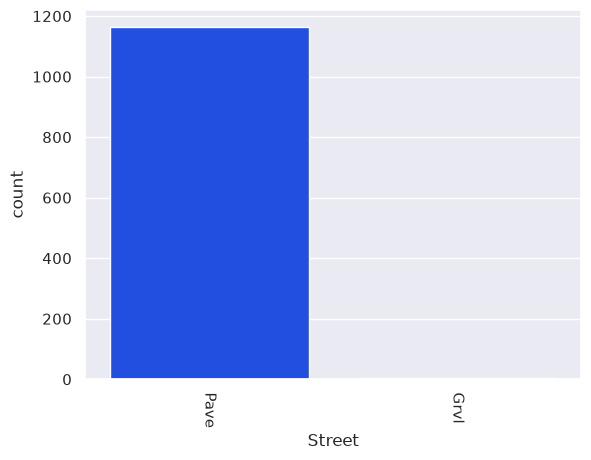

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


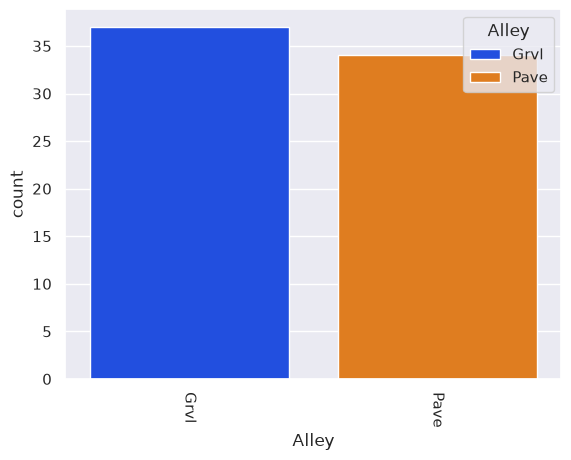

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


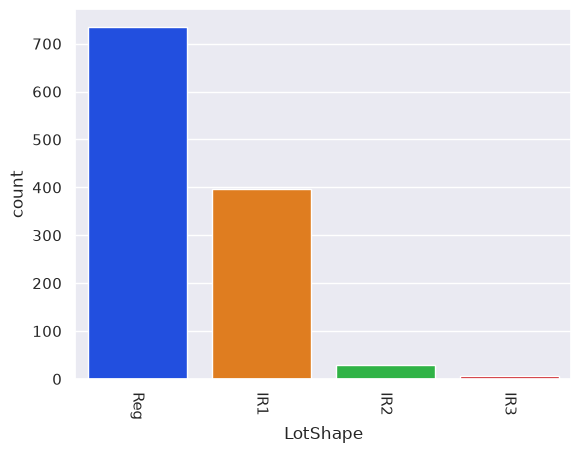

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


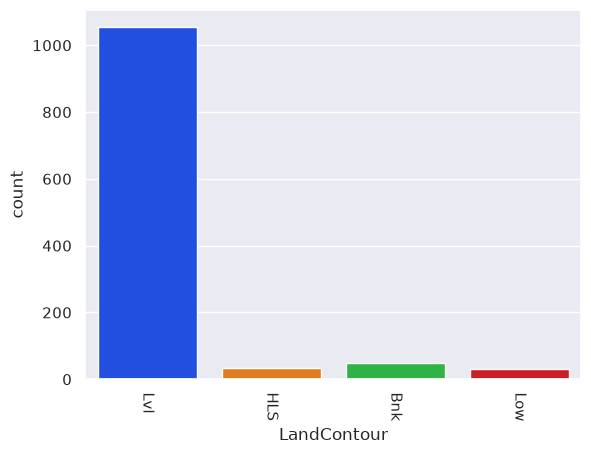

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


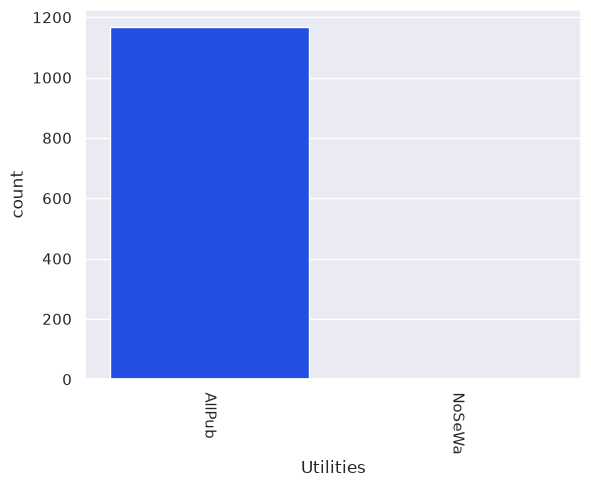

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


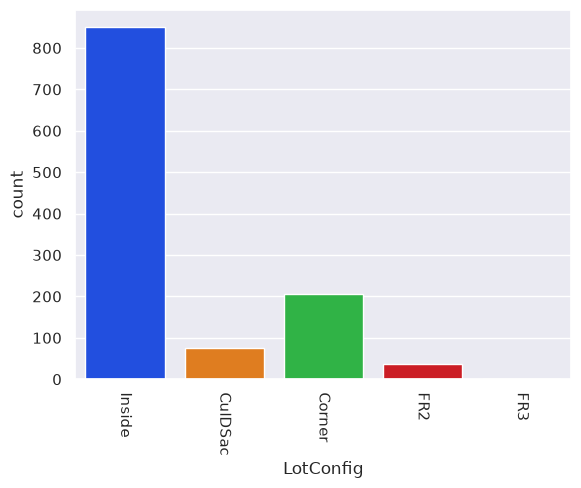

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


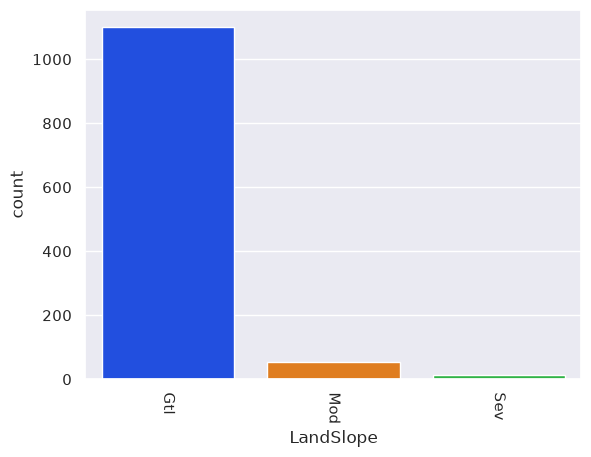

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: 
The palette list has fewer values (10) than needed (25) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


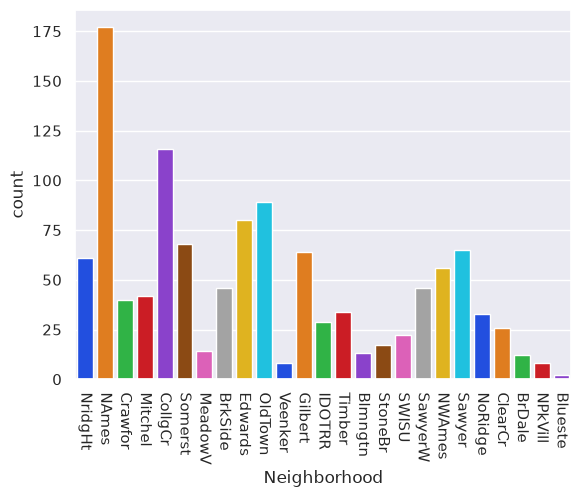

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


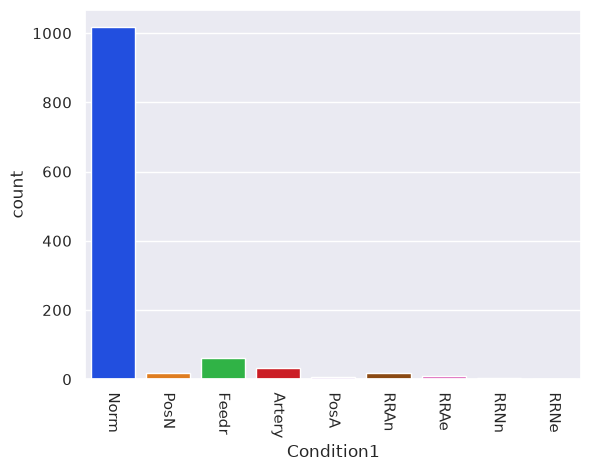

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


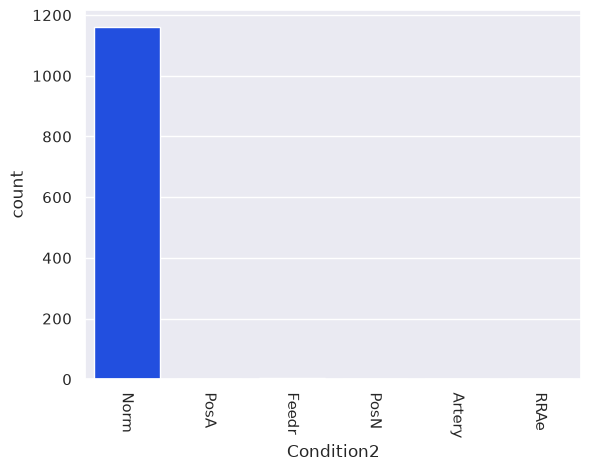

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


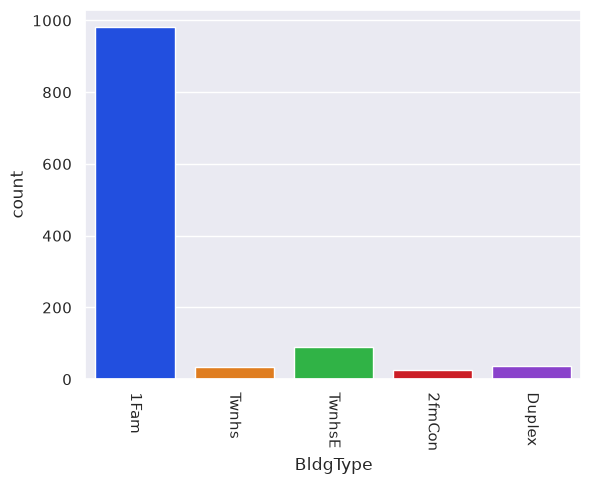

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


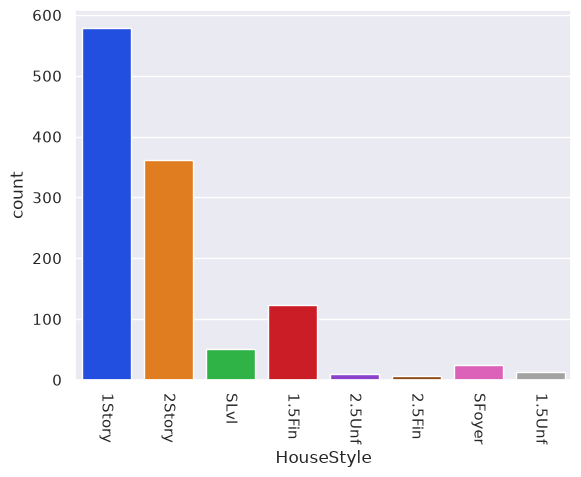

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


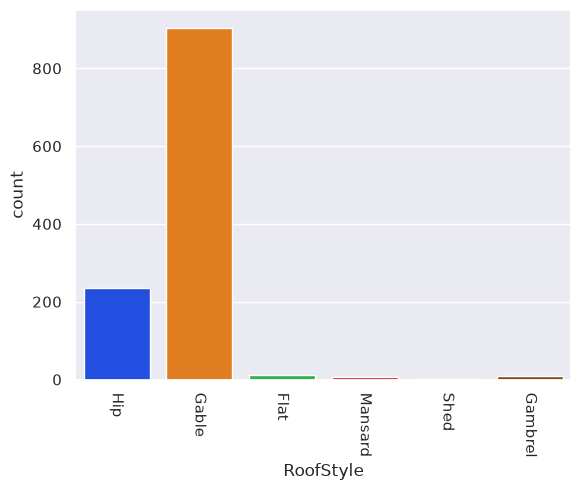

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


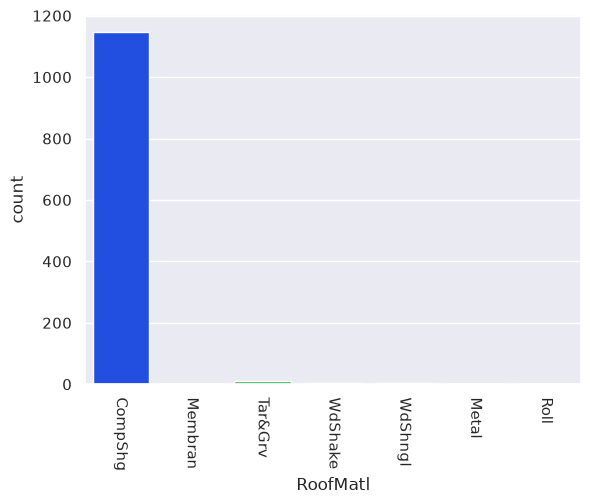

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: 
The palette list has fewer values (10) than needed (15) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


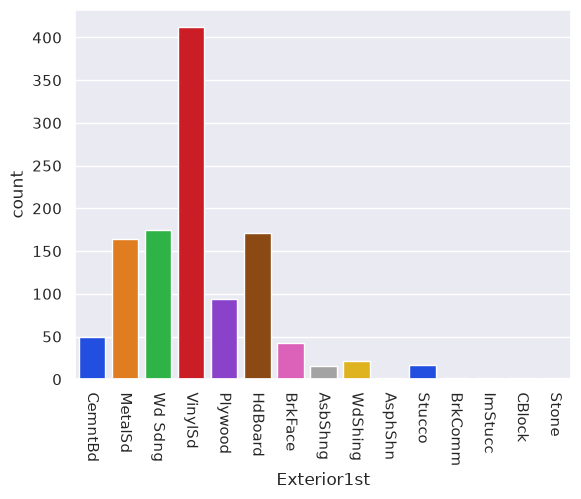

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: 
The palette list has fewer values (10) than needed (16) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


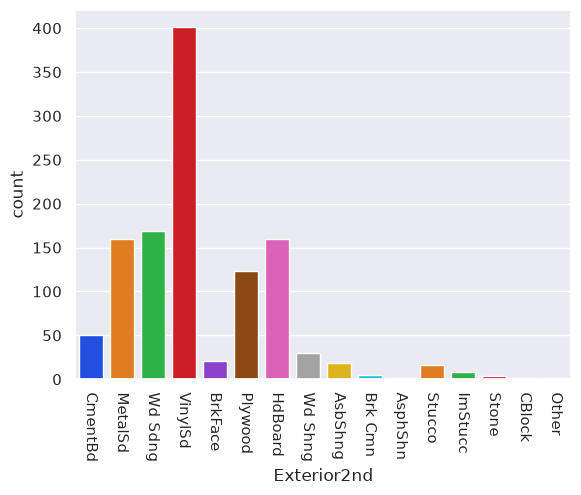

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


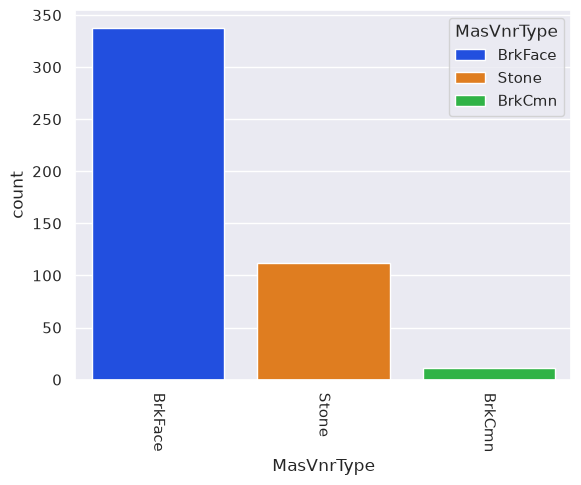

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


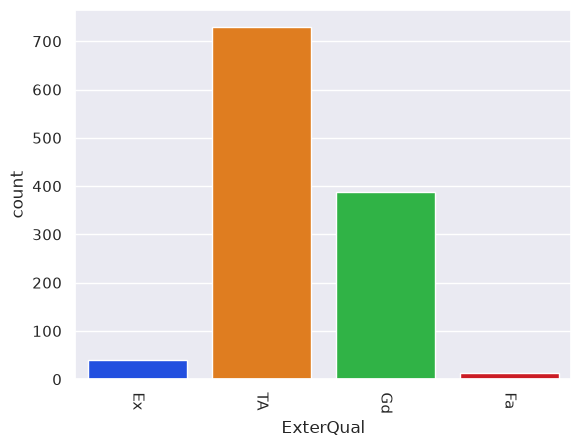

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


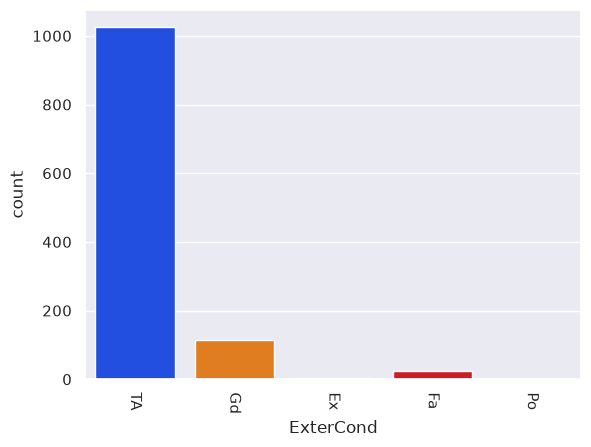

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


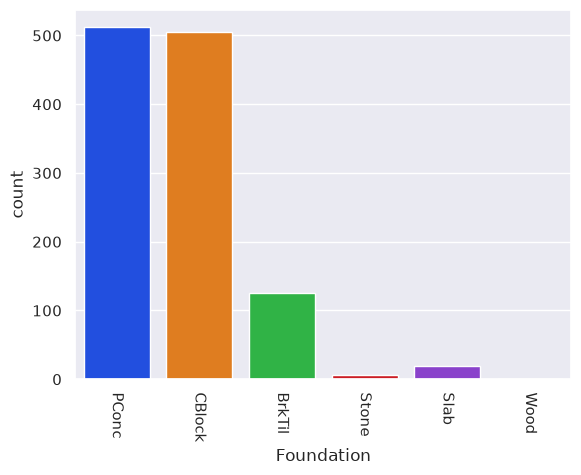

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


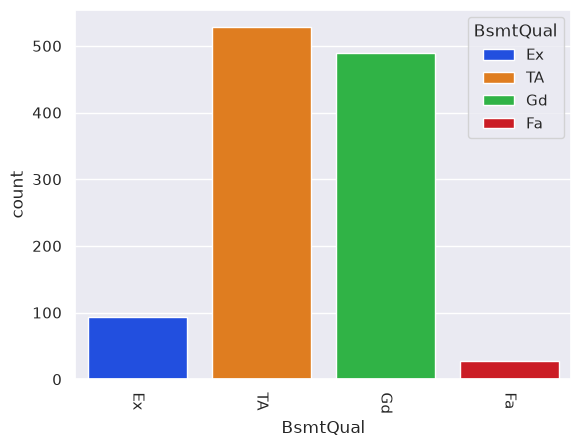

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


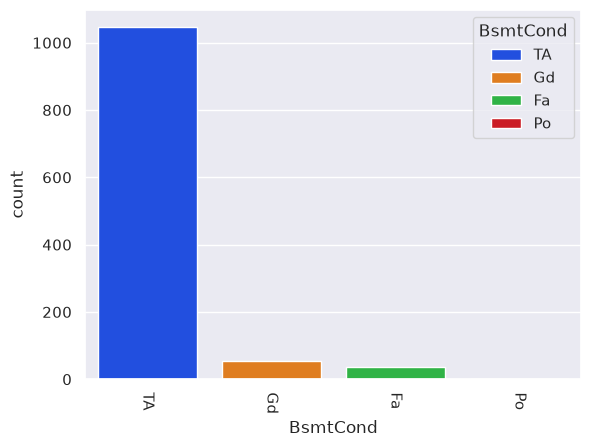

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


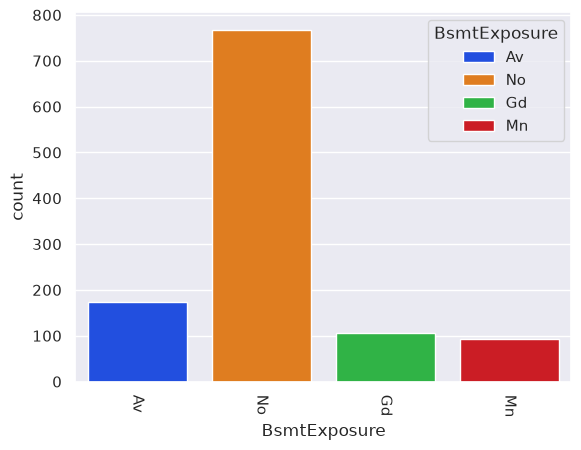

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


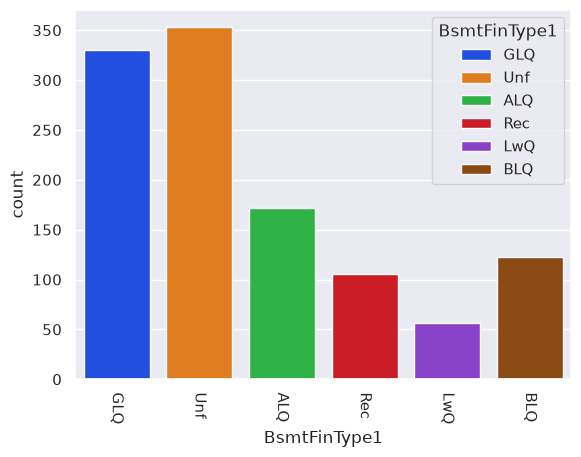

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


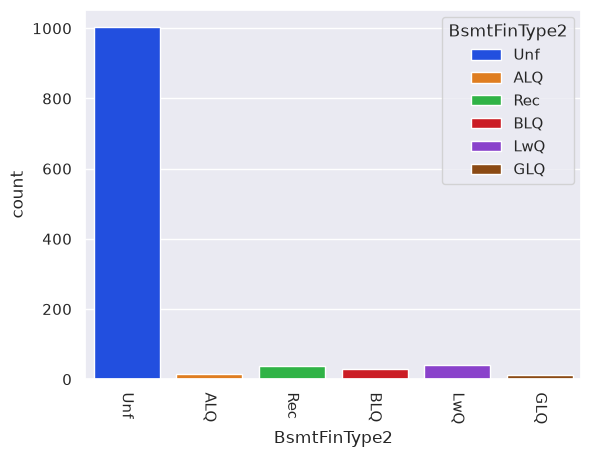

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


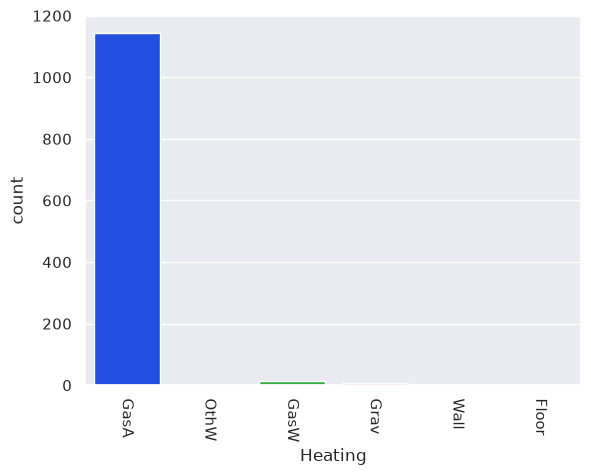

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


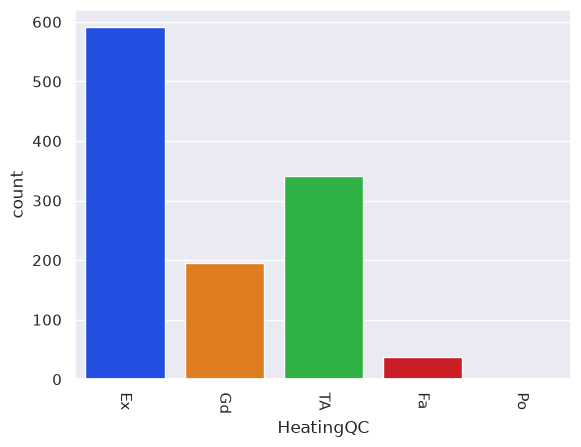

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


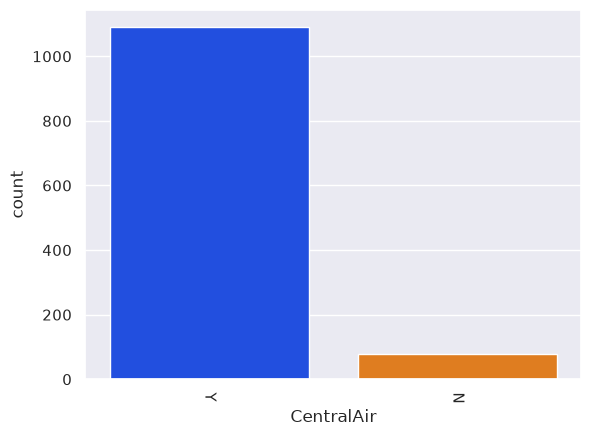

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


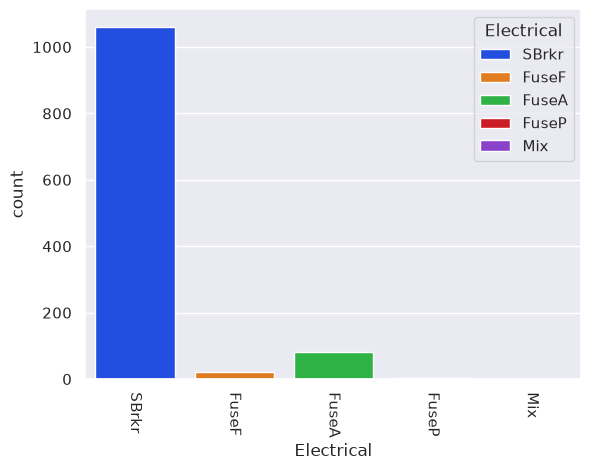

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


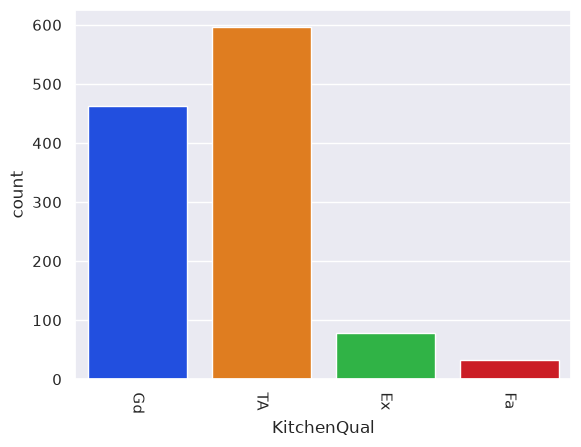

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


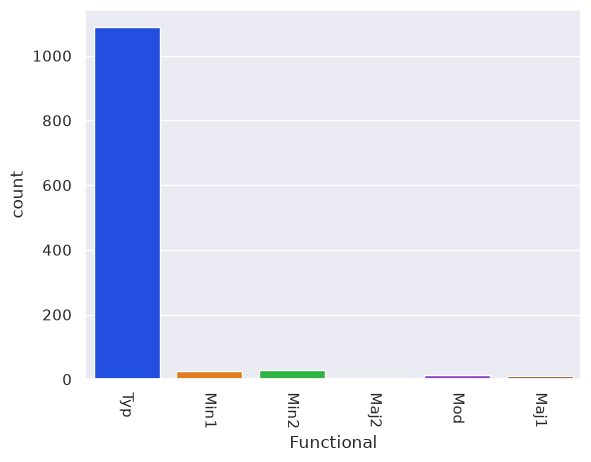

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


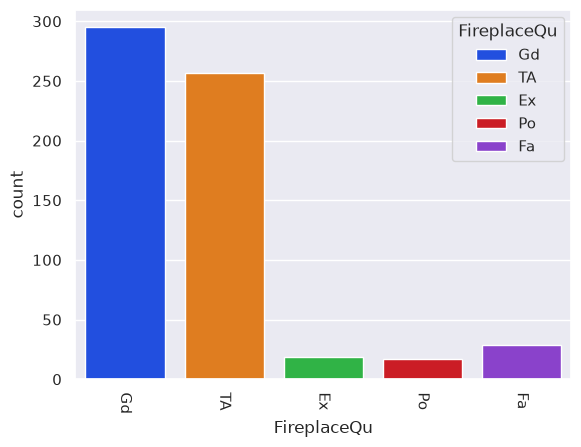

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


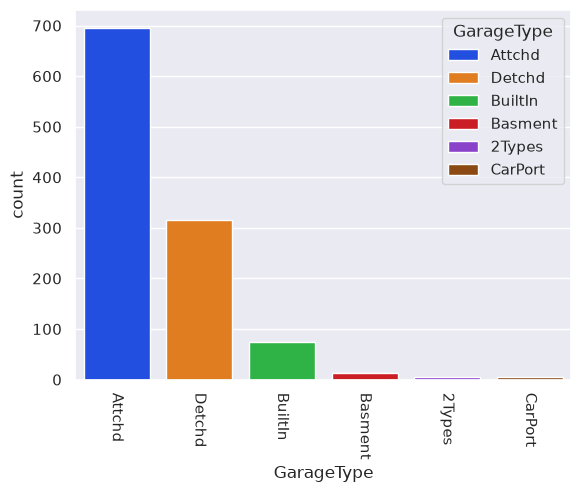

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


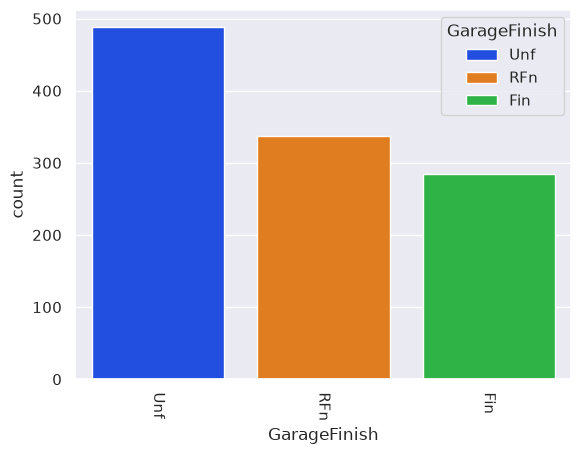

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


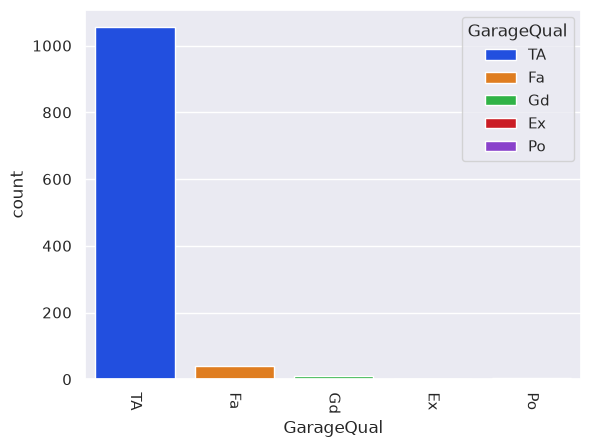

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


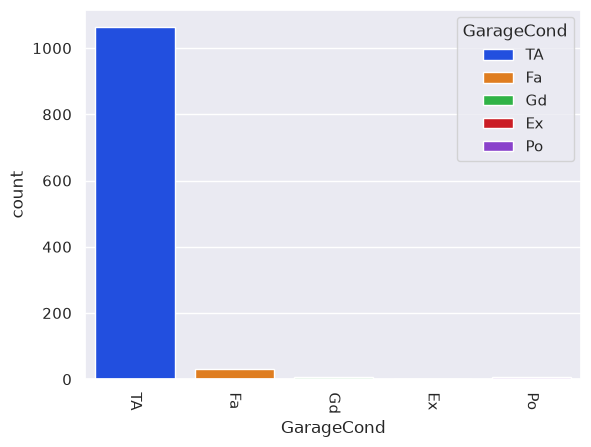

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


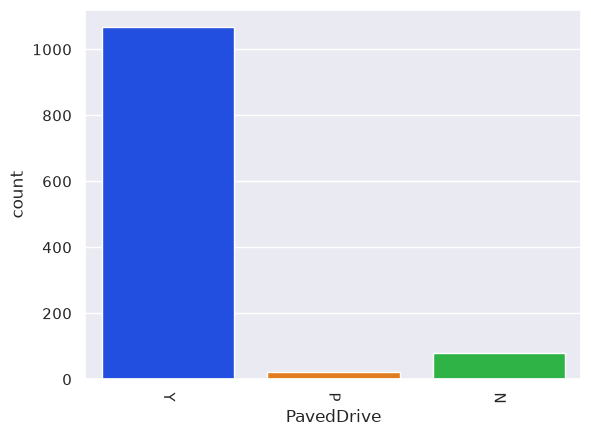

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


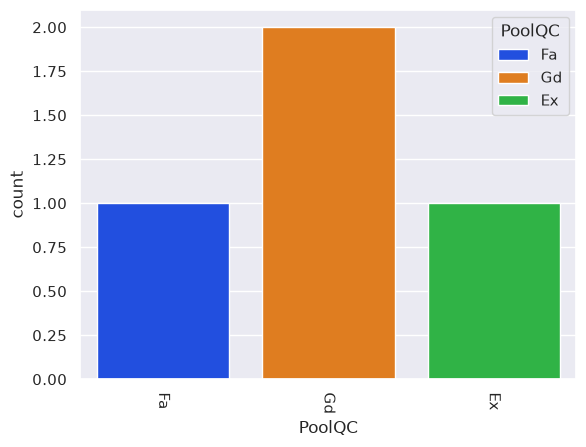

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


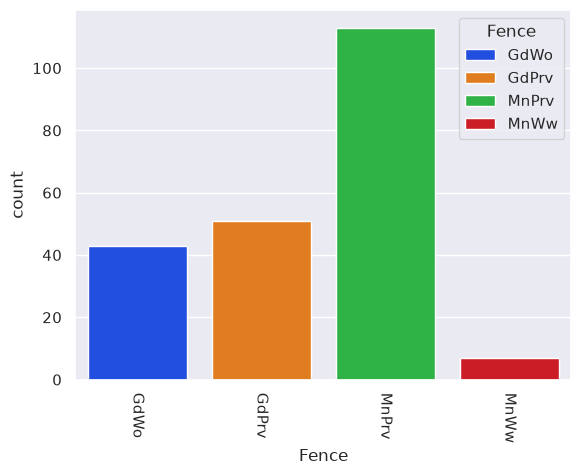

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


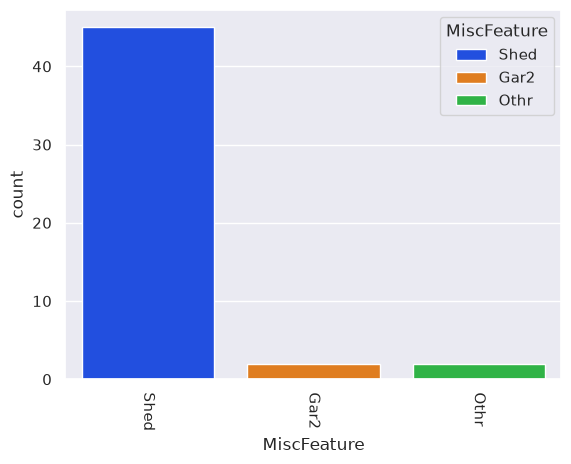

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


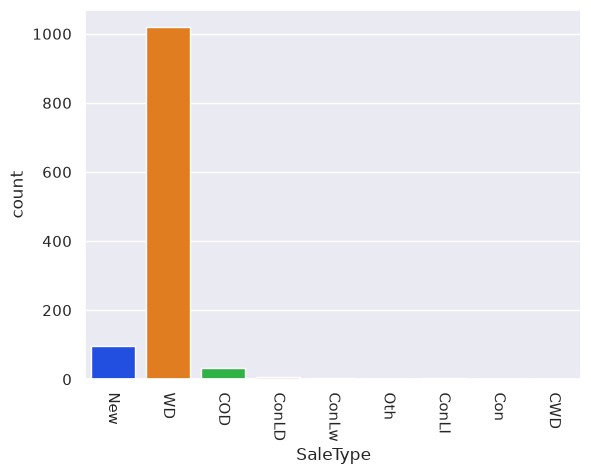

/tmp/ipykernel_16690/3923412066.py:2: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.countplot(data=X_train, x=col, hue=col, palette=colours)


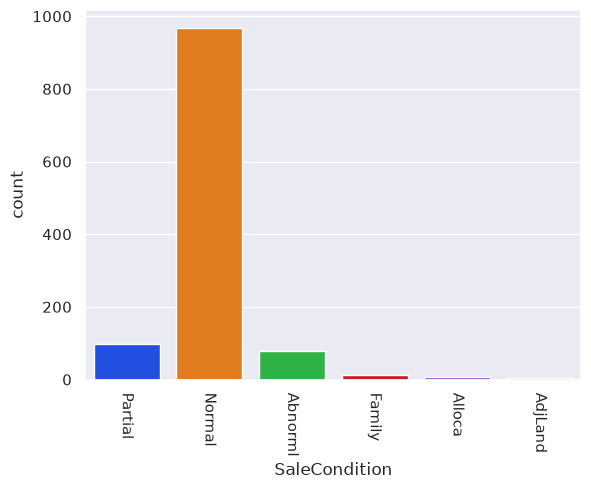

In [71]:
for col in CATERGORICAL_COLUMNS:
    sns.countplot(data=X_train, x=col, hue=col, palette=colours)
    plt.xticks(rotation=-90)
    plt.show()
    

## Bi-variate analysis
### Continous analysis

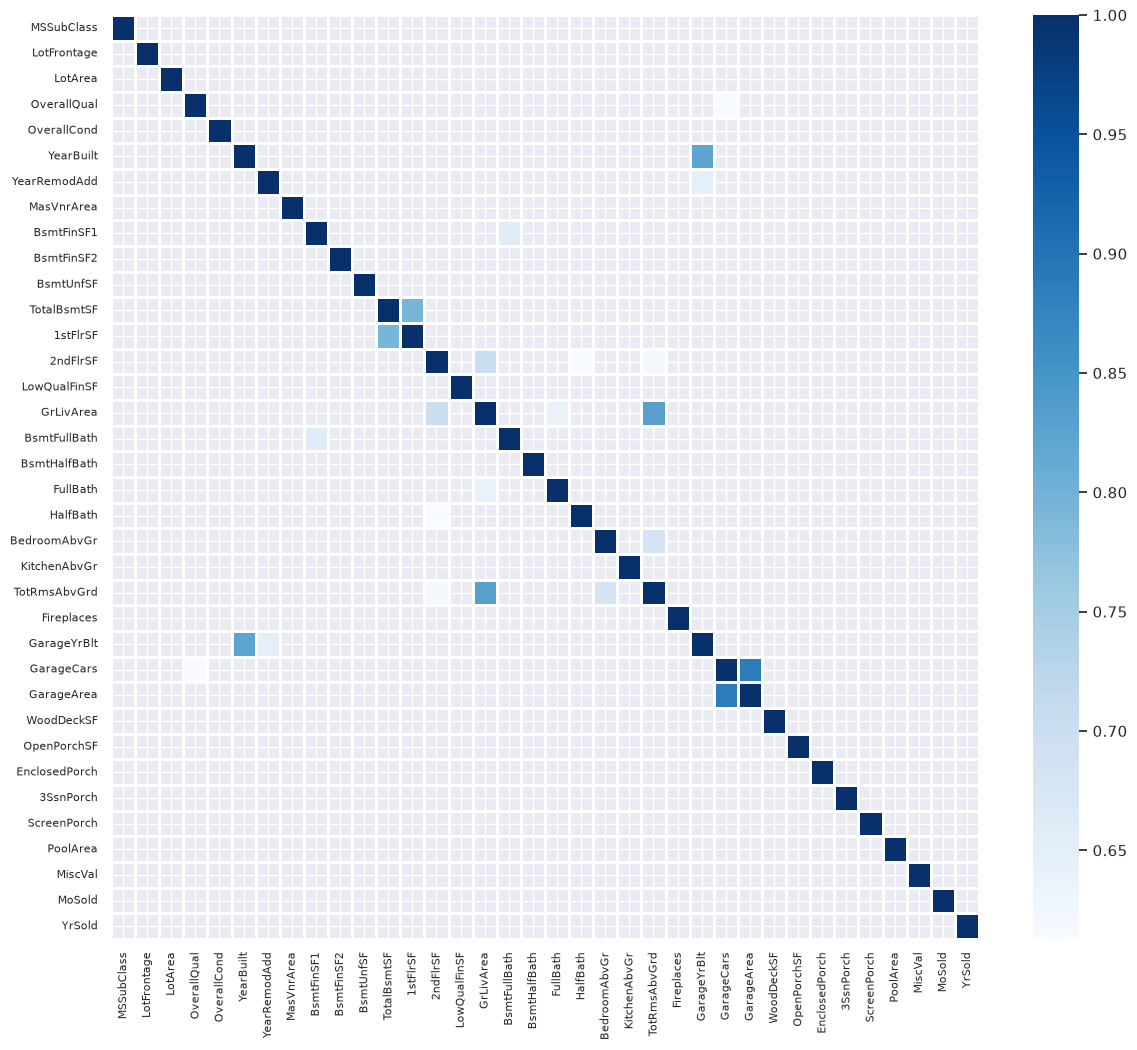

In [72]:
corr = X_train[NUMERICAL_COLUMNS].corr()
mask = corr < 0.6
plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap='Blues', mask=mask,xticklabels=True, yticklabels=True, linewidths=0.8).tick_params(axis='both', labelsize=8) 
plt.show()



In [73]:
X_y_train = pd.concat([X_train[NUMERICAL_COLUMNS], y_train], axis=1)
X_y_train.head()


corr = X_y_train.corr()
corr['SalePrice'].sort_values(ascending=False)


SalePrice        1.000000
OverallQual      0.790636
GrLivArea        0.721707
GarageCars       0.660927
GarageArea       0.646603
TotalBsmtSF      0.635535
1stFlrSF         0.620740
FullBath         0.578134
TotRmsAbvGrd     0.542658
YearBuilt        0.521242
YearRemodAdd     0.517822
GarageYrBlt      0.494154
MasVnrArea       0.493482
Fireplaces       0.470320
BsmtFinSF1       0.401390
LotFrontage      0.360274
OpenPorchSF      0.320193
2ndFlrSF         0.320141
WoodDeckSF       0.311813
HalfBath         0.283762
LotArea          0.252766
BsmtFullBath     0.226432
BsmtUnfSF        0.206736
BedroomAbvGr     0.182258
ScreenPorch      0.096740
3SsnPorch        0.057561
MoSold           0.041369
PoolArea         0.027441
BsmtHalfBath    -0.010994
BsmtFinSF2      -0.020622
LowQualFinSF    -0.023128
MiscVal         -0.024750
YrSold          -0.045628
OverallCond     -0.053643
MSSubClass      -0.084312
EnclosedPorch   -0.129519
KitchenAbvGr    -0.136104
Name: SalePrice, dtype: float64

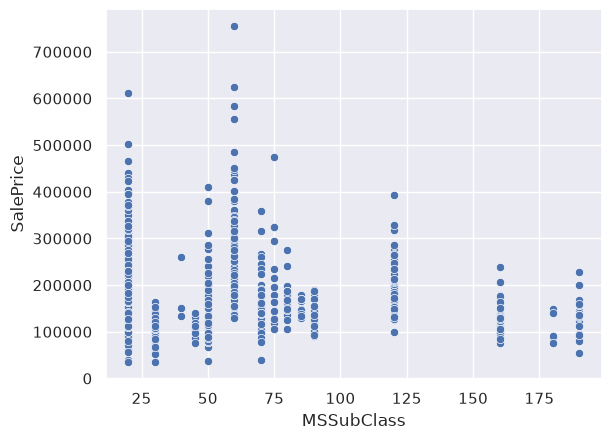

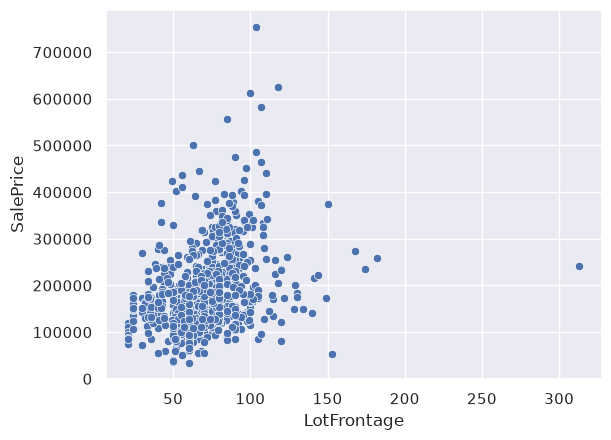

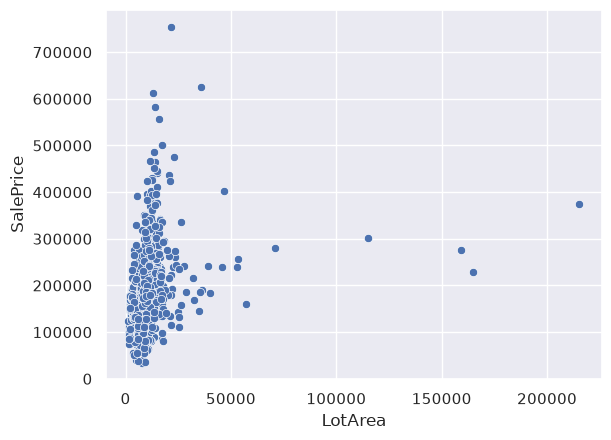

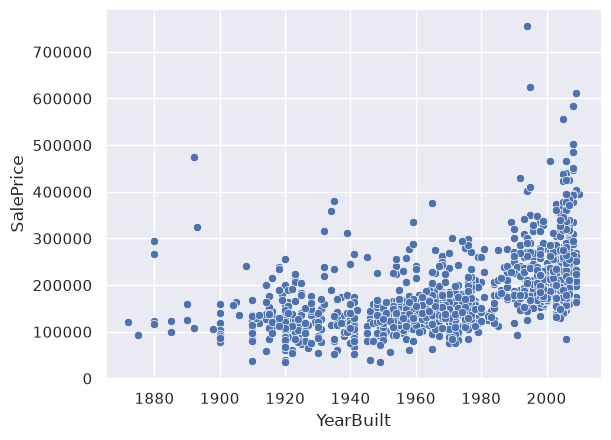

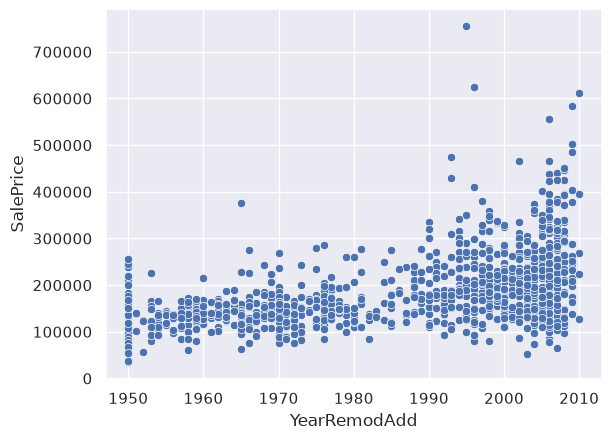

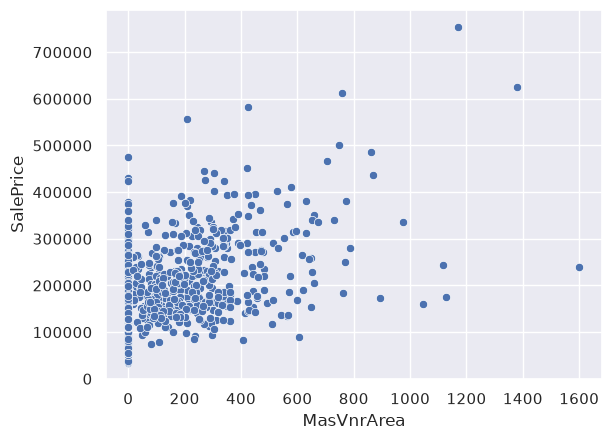

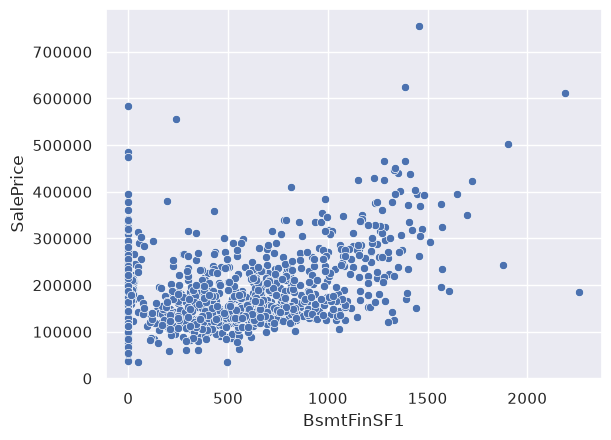

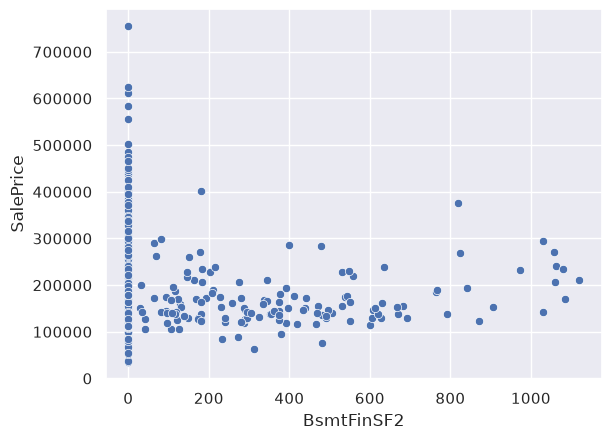

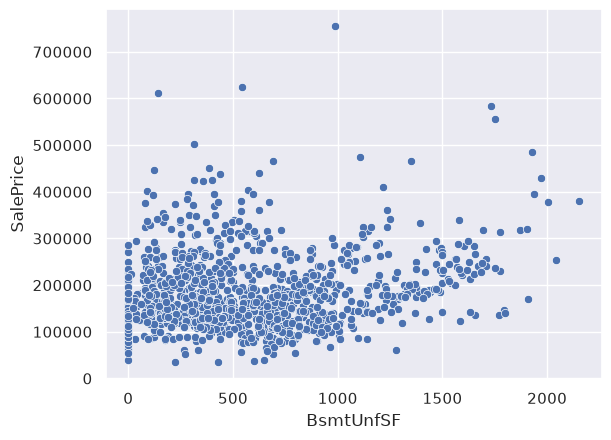

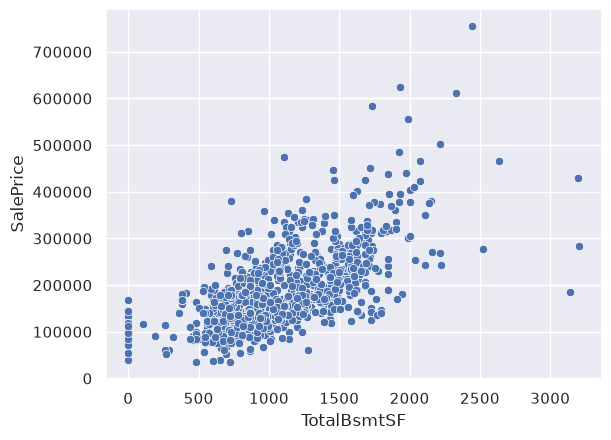

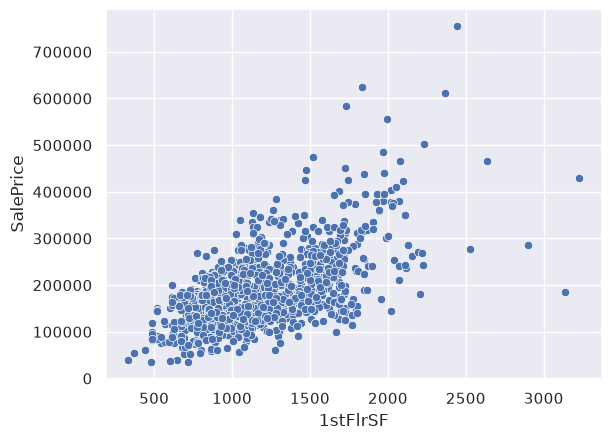

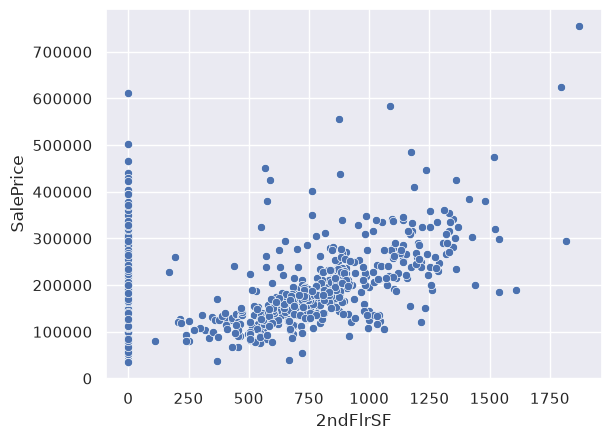

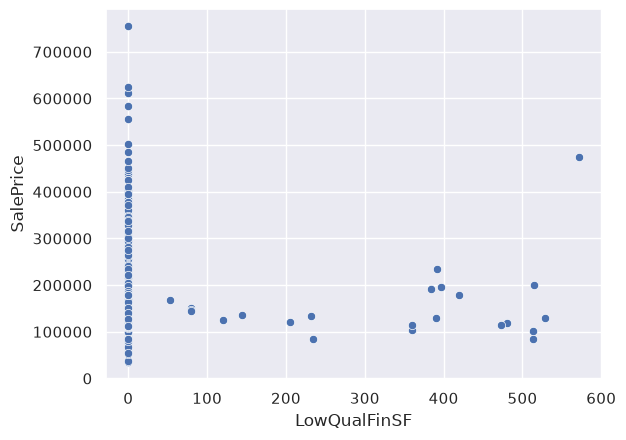

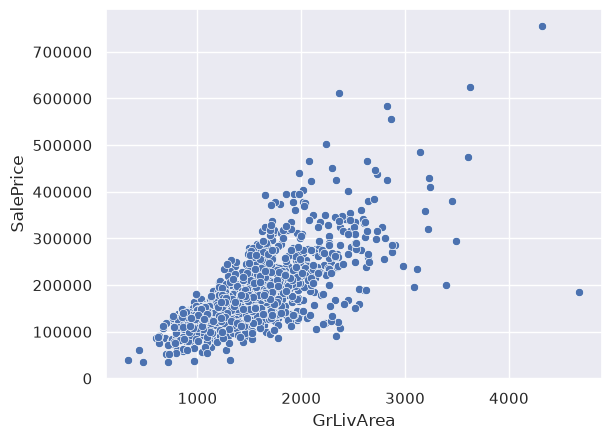

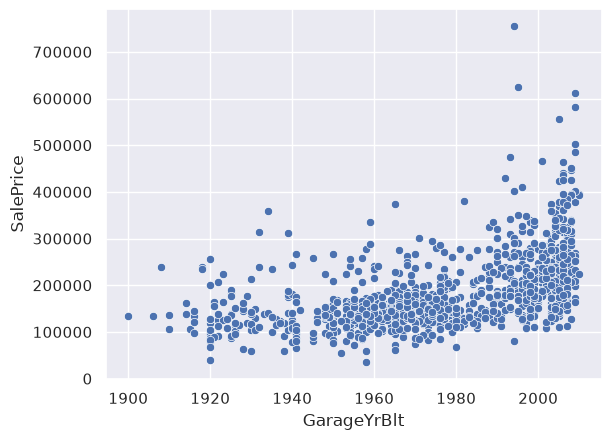

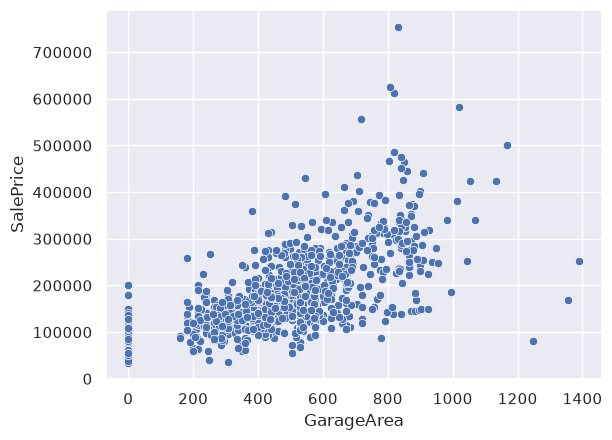

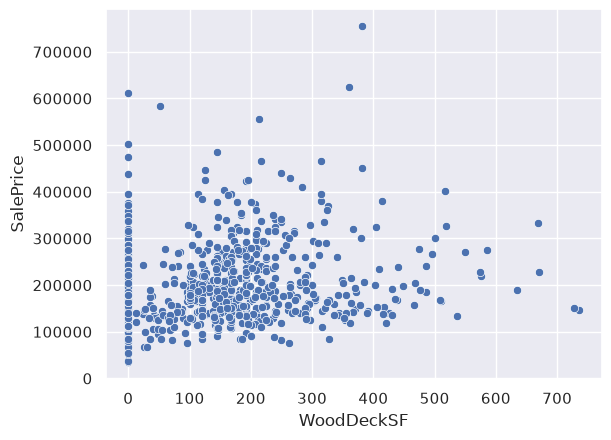

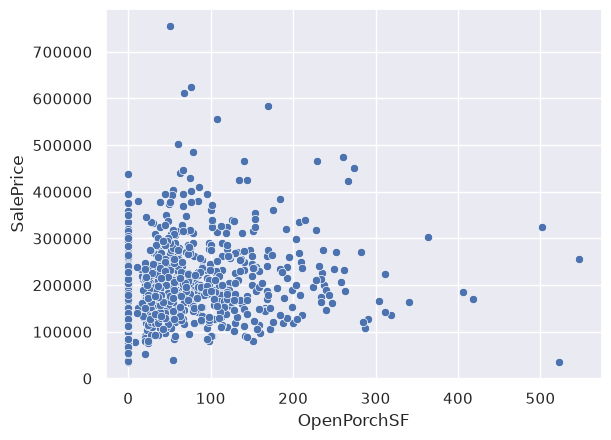

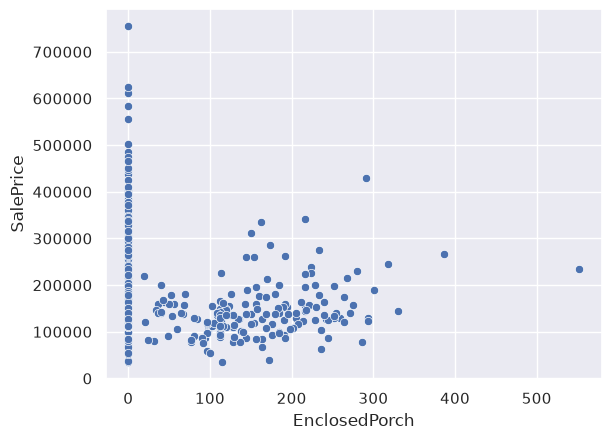

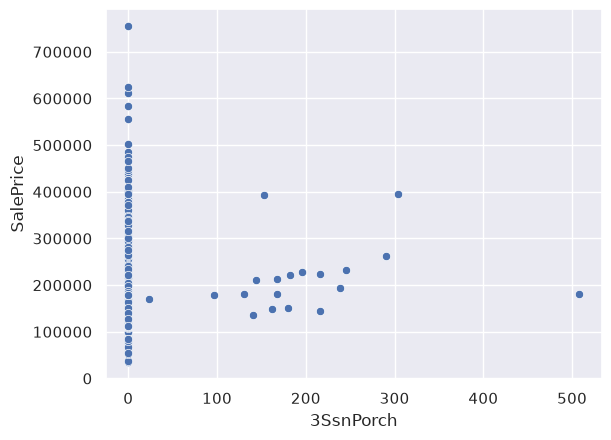

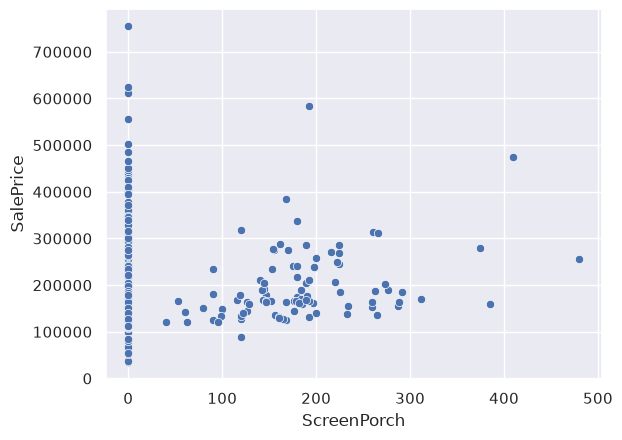

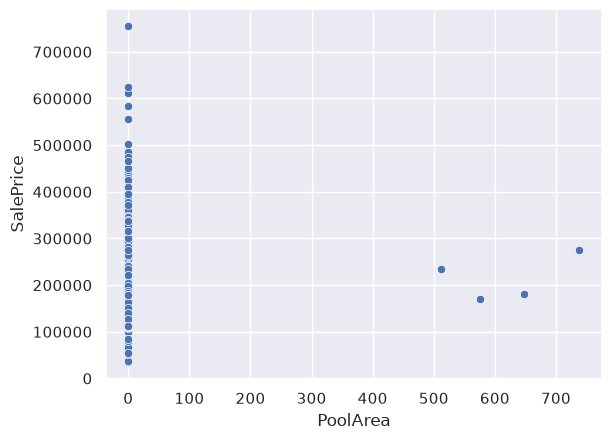

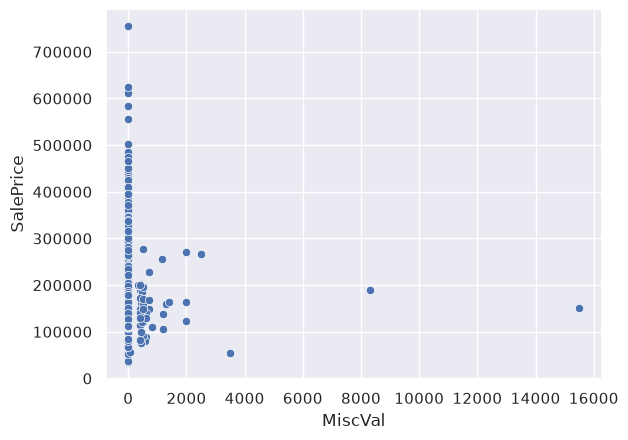

In [74]:
for col in CONT_NUM_COLS:
    sns.scatterplot(data=X_y_train, x=col, y='SalePrice')
    plt.show()